<a href="https://colab.research.google.com/github/mlorup/test-project/blob/main/Rigi_Daten_Visualisierung_RDF_Agent_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Insurance Analytics Lab · Von Zufallsdaten zum kontextgestützten Agenten
**CAS Enterprise Scale Data & AI · HWZ**

**Auf Basis der Vorlage von Claudio Mirti · Rigi International Insurance**

---

## Der Fall: «Rigi International Insurance»
Die **Rigi International Insurance** ist ein fiktiver Versicherer mit Kunden in
**7 europäischen Ländern**: Schweiz, Deutschland, Österreich, Italien,
Frankreich, Spanien und Niederlande.

Die Geschäftsleitung fragt:
1. Wo entstehen Schäden, und welche Gefahren verursachen den höchsten Aufwand?
2. Wie unterscheiden sich die Schadenquoten zwischen Ländern?
3. Welche Zusammenhänge zwischen Kunden, Policen, Schäden und Dienstleistern
   sollte ein Analyst prüfen?
4. Wie kann ein Agent diese Fragen mit **explizitem Fachkontext und Belegen**
   beantworten, statt Zusammenhänge zu erfinden?

## Der Lernpfad
**Zufallsdaten → Visualisierung → Ontologie/RDF → Wissensgraph → Agentensimulation**

| Teil | Inhalt | Werkzeuge |
|---|---|---|
| 1 | Umgebung vorbereiten | `pip`, Python |
| 2 | Reproduzierbare Versicherungsdaten erzeugen und prüfen | `numpy`, `pandas` |
| 3 | Verteilungen, Zeitreihen und Kennzahlen visualisieren | `matplotlib`, `seaborn` |
| 4 | Geografische Zusammenhänge darstellen | `folium`, OpenStreetMap/CARTO |
| 5 | Fachbegriffe und Beziehungen als Ontologie/RDF modellieren | `rdflib`, OWL, SPARQL |
| 6 | Wissensgraph visualisieren und Auffälligkeiten untersuchen | `networkx`, `pyvis` |
| 7 | Einen Agenten simulieren, der RDF-Kontext tatsächlich abfragt | Python, SPARQL, Belege |

## Ausführung in Google Colaboratory
- Öffne [Google Colab](https://colab.research.google.com/), wähle
  **Datei → Notebook hochladen** und lade diese `.ipynb`-Datei hoch.
- Nutze eine **Python-3-CPU-Laufzeit**. Es sind keine GPU, Zugangsdaten,
  Cloud-Ressourcen oder API-Schlüssel erforderlich.
- Wähle **Laufzeit → Alle ausführen**, oder führe die Zellen mit
  **Shift + Enter** der Reihe nach aus.
- Internet wird für die Paketinstallation, Ländergrenzen und Kartenkacheln
  benötigt. Die Agentensimulation selbst läuft anschliessend lokal im Kernel.
- Ein Durchlauf benötigt normalerweise wenige Minuten. Die Datengenerierung
  startet bei jedem vollständigen Durchlauf mit **Seed 42**.

> Alle Geschäftsdaten sind **synthetisch**. Risikoprofile, Prüfregeln und
> Auffälligkeiten sind didaktische Annahmen, keine Aussagen über echte Länder,
> Personen oder Unternehmen. Der Agent ist **regelbasiert simuliert**:
> kein LLM, keine automatische Betrugsentscheidung und keine externen Aktionen.

---
# Teil 1 · Bibliotheken laden
Die erste Code-Zelle installiert alle benötigten Bibliotheken direkt in den
aktiven Notebook-Kernel. `%pip` funktioniert in Google Colab und Jupyter.
Die Versionsbereiche vermeiden bekannte API-Unterschiede zur Vorlage.
Die Installation benötigt Internet und dauert beim ersten Mal etwas länger.

In [2]:
%pip install -q "numpy>=1.26,<3" "pandas>=2.2,<3" "matplotlib>=3.8,<4" "seaborn>=0.13.2,<0.14" "folium>=0.17,<0.21" "networkx>=3.3,<4" "pyvis==0.3.2" "rdflib>=7.1,<8"

### 1.1 pandas: Tabellen
**pandas** ist das «Excel von Python»: Damit arbeiten wir mit Tabellen (sogenannten *DataFrames*).
Wir importieren es unter dem Kurznamen `pd` und geben die Version aus.

In [4]:
import pandas as pd
print("pandas Version:", pd.__version__)

pandas Version: 2.2.3


### 1.2 numpy: Zahlen und Zufall
**numpy** rechnet schnell mit Zahlen. Wir brauchen es, um realistische Zufallsdaten zu erzeugen.

In [5]:
import numpy as np
print("numpy Version:", np.__version__)

numpy Version: 2.4.6


### 1.3 matplotlib: Grundlage für Diagramme
**matplotlib** zeichnet Diagramme. `plt` ist der übliche Kurzname.

In [6]:
import matplotlib.pyplot as plt
import matplotlib
print("matplotlib Version:", matplotlib.__version__)

matplotlib Version: 3.10.0


### 1.4 seaborn: schöne statistische Diagramme
**seaborn** baut auf matplotlib auf und macht mit wenig Code ansprechende Grafiken.
Mit `set_theme` legen wir einen einheitlichen Stil für alle Diagramme fest.

In [7]:
import seaborn as sns
sns.set_theme(style="whitegrid", palette="Set2")
print("seaborn Version:", sns.__version__)

seaborn Version: 0.13.2


### 1.5 folium: interaktive Karten mit OpenStreetMap
**folium** erstellt Karten im Browser auf Basis von **OpenStreetMap**, einer freien Open-Source-Weltkarte.

In [8]:
import folium
from folium.plugins import HeatMap
print("folium Version:", folium.__version__)

folium Version: 0.20.0


### 1.6 networkx: Graphen und Netzwerke
**networkx** speichert und analysiert Netzwerke: Knoten (z.B. Kunden) und Kanten (z.B. «hat Police»).

In [9]:
import networkx as nx
print("networkx Version:", nx.__version__)

networkx Version: 3.7


### 1.7 pyvis: interaktive Graph-Visualisierung
**pyvis** zeigt Netzwerke interaktiv an: Du kannst Knoten verschieben, zoomen und Details ansehen.
`HTML` und `display` brauchen wir, um die Grafik direkt im Notebook anzuzeigen.

In [10]:
from pyvis.network import Network
from IPython.display import HTML, display
print("pyvis geladen ✔")

pyvis geladen ✔


### 1.8 rdflib: Ontologien (RDF / OWL)
**rdflib** ist die Standard-Bibliothek für **Ontologien** und **Wissensgraphen**.
- `Graph`: der Wissensgraph
- `Namespace`: ein eigener «Namensraum» für unsere Begriffe
- `RDF`, `RDFS`, `OWL`, `XSD`: Standard-Vokabulare des Semantic Web

In [11]:
from rdflib import Graph, Namespace, Literal, RDF, RDFS, OWL, XSD
import rdflib
print("rdflib Version:", rdflib.__version__)

rdflib Version: 7.6.0


### 1.9 Zufallsgenerator fixieren
Wir setzen einen **Seed** (Startwert). So erhalten alle Teilnehmenden **exakt dieselben Zufallsdaten** und dieselben Ergebnisse.

In [12]:
rng = np.random.default_rng(seed=42)
print("Zufallsgenerator bereit, Seed = 42")

Zufallsgenerator bereit, Seed = 42


---
# Teil 2 · Versicherungsdaten erzeugen und kennenlernen
Wir erzeugen **fünf verknüpfte Tabellen**, statt echte Geschäftsdaten zu laden.

| Tabelle | Inhalt | Quelle in der Praxis |
|---|---|---|
| `staedte` | Städte mit Land und Koordinaten | Geodaten |
| `kunden` | Kundinnen und Kunden | CRM |
| `policen` | Versicherungsverträge mit Jahresprämie | Policenverwaltung |
| `werkstaetten` | Werkstätten und allgemeine Schaden-Dienstleister | Partnerverwaltung |
| `schaeden` | Schadenfälle mit Gefahr, Betrag und Dienstleister | Schadensystem |

**Vereinfachungen:** Alle Beträge werden in EUR simuliert, auch für die Schweiz.
Alle Policen gelten für die vollen Jahre 2024 und 2025 mit konstanter Jahresprämie.
Kosten, Rückversicherung, Reserven und Deckungsdetails werden nicht modelliert.
«Werkstatt» steht im Folgenden auch für andere Schaden-Dienstleister.

### 2.1 Städte mit Koordinaten
Jede Stadt hat ein **Land**, einen **ISO-Ländercode** (z.B. CHE = Schweiz) und **Koordinaten** (Breitengrad *lat*, Längengrad *lon*) für die Karte.

In [13]:
staedte = pd.DataFrame([
    ("Zürich",     "Schweiz",     "CHE", 47.3769,  8.5417), ("Bern",      "Schweiz",     "CHE", 46.9480,  7.4474),
    ("Genève",     "Schweiz",     "CHE", 46.2044,  6.1432), ("Lugano",    "Schweiz",     "CHE", 46.0037,  8.9511),
    ("München",    "Deutschland", "DEU", 48.1351, 11.5820), ("Berlin",    "Deutschland", "DEU", 52.5200, 13.4050),
    ("Hamburg",    "Deutschland", "DEU", 53.5511,  9.9937), ("Köln",      "Deutschland", "DEU", 50.9375,  6.9603),
    ("Wien",       "Österreich",  "AUT", 48.2082, 16.3738), ("Graz",      "Österreich",  "AUT", 47.0707, 15.4395),
    ("Innsbruck",  "Österreich",  "AUT", 47.2692, 11.4041), ("Milano",    "Italien",     "ITA", 45.4642,  9.1900),
    ("Roma",       "Italien",     "ITA", 41.9028, 12.4964), ("Napoli",    "Italien",     "ITA", 40.8518, 14.2681),
    ("Paris",      "Frankreich",  "FRA", 48.8566,  2.3522), ("Lyon",      "Frankreich",  "FRA", 45.7640,  4.8357),
    ("Nice",       "Frankreich",  "FRA", 43.7102,  7.2620), ("Madrid",    "Spanien",     "ESP", 40.4168, -3.7038),
    ("Valencia",   "Spanien",     "ESP", 39.4699, -0.3763), ("Amsterdam", "Niederlande", "NLD", 52.3676,  4.9041),
    ("Rotterdam",  "Niederlande", "NLD", 51.9244,  4.4777),
], columns=["stadt", "land", "iso3", "lat", "lon"])
staedte

,stadt,land,iso3,lat,lon
0,Zürich,Schweiz,CHE,47.3769,8.5417
1,Bern,Schweiz,CHE,46.9480,7.4474
2,Genève,Schweiz,CHE,46.2044,6.1432
3,Lugano,Schweiz,CHE,46.0037,8.9511
4,München,Deutschland,DEU,48.1351,11.5820
5,Berlin,Deutschland,DEU,52.5200,13.4050
6,Hamburg,Deutschland,DEU,53.5511,9.9937
7,Köln,Deutschland,DEU,50.9375,6.9603
8,Wien,Österreich,AUT,48.2082,16.3738
9,Graz,Österreich,AUT,47.0707,15.4395


### 2.2 Wie viele Städte pro Land?
`value_counts()` zählt, wie oft jeder Wert vorkommt.

In [14]:
staedte["land"].value_counts()

,count
land,
Schweiz,4
Deutschland,4
Österreich,3
Italien,3
Frankreich,3
Spanien,2
Niederlande,2


### 2.3 Naturgefahren pro Land
Wir legen **frei erfundene Wahrscheinlichkeiten** für sieben Schadenursachen
fest. Jede Zeile ergibt 1 = 100%. Diese Profile dienen nur dem Unterricht und
sind keine empirischen Länderrisiken. Kollision ist im vereinfachten Modell
ausschliesslich in der Sparte Motorfahrzeug möglich; bei den anderen Sparten
werden die verbleibenden Wahrscheinlichkeiten in Teil 2.10 neu normiert.

In [15]:
gefahren_profil = pd.DataFrame({
    #               Hagel  Sturm  Hochwasser  Erdbeben  Waldbrand  Diebstahl  Kollision
    "Schweiz":     [0.30,  0.10,  0.10,       0.00,     0.00,      0.15,      0.35],
    "Deutschland": [0.12,  0.25,  0.15,       0.00,     0.00,      0.15,      0.33],
    "Österreich":  [0.22,  0.12,  0.20,       0.00,     0.00,      0.12,      0.34],
    "Italien":     [0.10,  0.08,  0.14,       0.12,     0.04,      0.20,      0.32],
    "Frankreich":  [0.08,  0.24,  0.12,       0.00,     0.06,      0.18,      0.32],
    "Spanien":     [0.04,  0.08,  0.08,       0.02,     0.20,      0.22,      0.36],
    "Niederlande": [0.04,  0.28,  0.22,       0.00,     0.00,      0.14,      0.32],
}, index=["Hagel", "Sturm", "Hochwasser", "Erdbeben", "Waldbrand", "Diebstahl", "Kollision"]).T
gefahren_profil

,Hagel,Sturm,Hochwasser,Erdbeben,Waldbrand,Diebstahl,Kollision
Schweiz,0.30,0.10,0.10,0.00,0.00,0.15,0.35
Deutschland,0.12,0.25,0.15,0.00,0.00,0.15,0.33
Österreich,0.22,0.12,0.20,0.00,0.00,0.12,0.34
Italien,0.10,0.08,0.14,0.12,0.04,0.20,0.32
Frankreich,0.08,0.24,0.12,0.00,0.06,0.18,0.32
Spanien,0.04,0.08,0.08,0.02,0.20,0.22,0.36
Niederlande,0.04,0.28,0.22,0.00,0.00,0.14,0.32


### 2.4 Kontrolle: Ergibt jede Zeile 100%?
Gute Datenqualität beginnt mit Prüfungen. Jede Zeile sollte die Summe **1.0** haben.

In [16]:
assert np.allclose(gefahren_profil.sum(axis=1), 1.0), "Gefahrenprofile müssen 100% ergeben."
gefahren_profil.sum(axis=1)

,0
Schweiz,1.0
Deutschland,1.0
Österreich,1.0
Italien,1.0
Frankreich,1.0
Spanien,1.0
Niederlande,1.0


### 2.5 Kunden erzeugen (CRM)
Wir erzeugen **4'000 Kunden**. Jeder wohnt zufällig in einer der Städte und gehört zu einem **Segment** (Privat oder KMU).

In [17]:
n_kunden = 4000
stadt_idx = rng.integers(0, len(staedte), n_kunden)
kunden = pd.DataFrame({
    "kunde_id": [f"K{1000+i}" for i in range(n_kunden)],
    "stadt":    staedte["stadt"].values[stadt_idx],
    "land":     staedte["land"].values[stadt_idx],
    "segment":  rng.choice(["Privat", "KMU"], n_kunden, p=[0.8, 0.2]),
})
kunden.head()

,kunde_id,stadt,land,segment
0,K1000,Bern,Schweiz,KMU
1,K1001,Nice,Frankreich,Privat
2,K1002,Napoli,Italien,KMU
3,K1003,Graz,Österreich,Privat
4,K1004,Graz,Österreich,Privat


### 2.6 Wie viele Kunden pro Land?

In [18]:
kunden["land"].value_counts()

,count
land,
Schweiz,775
Deutschland,734
Österreich,598
Frankreich,579
Italien,560
Niederlande,406
Spanien,348


### 2.7 Policen erzeugen (Policenverwaltung)
Jede Police gehört zu einem Kunden und deckt eine **Sparte**: Motorfahrzeug, Gebäude oder Hausrat.
Die **Prämie** (was der Kunde pro Jahr zahlt) hängt von der Sparte ab.

In [19]:
n_policen = 8000
policen = pd.DataFrame({
    "police_id": [f"P{20000+i}" for i in range(n_policen)],
    "kunde_id":  rng.choice(kunden["kunde_id"], n_policen),
    "sparte":    rng.choice(["Motorfahrzeug", "Gebäude", "Hausrat"], n_policen, p=[0.45, 0.30, 0.25]),
})
basis_praemie = {"Motorfahrzeug": 1100, "Gebäude": 1500, "Hausrat": 400}
policen["praemie_eur"] = (policen["sparte"].map(basis_praemie) * rng.lognormal(0, 0.25, n_policen)).round(0)
policen.head()

,police_id,kunde_id,sparte,praemie_eur
0,P20000,K3031,Gebäude,1545.0
1,P20001,K2821,Gebäude,1163.0
2,P20002,K1289,Motorfahrzeug,1792.0
3,P20003,K1475,Motorfahrzeug,1746.0
4,P20004,K3381,Motorfahrzeug,655.0


### 2.8 Land und Stadt an die Policen anhängen (Join)
Die Police kennt nur die `kunde_id`. Mit `merge` (wie SVERWEIS/VLOOKUP in Excel) holen wir **Stadt** und **Land** aus der Kundentabelle.

In [20]:
policen = policen.merge(
    kunden[["kunde_id", "stadt", "land"]],
    on="kunde_id", how="left", validate="many_to_one"
)
policen.head()

,police_id,kunde_id,sparte,praemie_eur,stadt,land
0,P20000,K3031,Gebäude,1545.0,Lugano,Schweiz
1,P20001,K2821,Gebäude,1163.0,Nice,Frankreich
2,P20002,K1289,Motorfahrzeug,1792.0,Graz,Österreich
3,P20003,K1475,Motorfahrzeug,1746.0,Nice,Frankreich
4,P20004,K3381,Motorfahrzeug,655.0,Graz,Österreich


### 2.9 Werkstätten / Dienstleister
Schäden werden von Werkstätten oder Handwerkern repariert. Wir erzeugen pro Stadt **2 Dienstleister**.
Später im Graphen werden wir sehen, ob einer davon **auffällig** ist.

In [21]:
werkstaetten = pd.DataFrame([
    {"werkstatt_id": f"W{i:02d}{j}", "name": f"Service {s['stadt']} {j}", "stadt": s["stadt"], "land": s["land"]}
    for i, s in staedte.iterrows() for j in ["A", "B"]
])
werkstaetten.head()

,werkstatt_id,name,stadt,land
0,W00A,Service Zürich A,Zürich,Schweiz
1,W00B,Service Zürich B,Zürich,Schweiz
2,W01A,Service Bern A,Bern,Schweiz
3,W01B,Service Bern B,Bern,Schweiz
4,W02A,Service Genève A,Genève,Schweiz


### 2.10 Schäden erzeugen (Schadensystem)
Jetzt das Herzstück: **1'500 Schadenfälle** in den Jahren 2024–2025.
Pro Schaden:
- eine zufällige Police (und damit Kunde, Land, Stadt)
- eine **Gefahr** gemäss Profil des Landes (Teil 2.3)
- ein **Betrag**: Erdbeben und Hochwasser sind teurer als Diebstahl
- ein **Datum**: Hagel passiert vor allem im Sommer, Sturm im Winter
- eine **Werkstatt** in derselben Stadt

In [22]:
n_schaeden = 1500
median_betrag = {
    "Hagel": 4500, "Sturm": 6000, "Hochwasser": 15000, "Erdbeben": 40000,
    "Waldbrand": 25000, "Diebstahl": 2500, "Kollision": 4000,
}
saison = {
    "Hagel": [5, 6, 7, 8], "Sturm": [1, 2, 3, 10, 11, 12],
    "Hochwasser": [4, 5, 6, 9, 10, 11], "Waldbrand": [6, 7, 8, 9],
}
werkstatt_pro_stadt = werkstaetten.groupby("stadt")["werkstatt_id"].agg(list)
zeilen = []
for i in range(n_schaeden):
    p = policen.iloc[int(rng.integers(0, len(policen)))]
    wahrscheinlichkeiten = gefahren_profil.loc[p["land"]].copy()
    if p["sparte"] != "Motorfahrzeug":
        wahrscheinlichkeiten.loc["Kollision"] = 0
    wahrscheinlichkeiten /= wahrscheinlichkeiten.sum()
    gefahr = rng.choice(wahrscheinlichkeiten.index, p=wahrscheinlichkeiten.to_numpy())
    monat = rng.choice(saison[gefahr]) if gefahr in saison else rng.integers(1, 13)
    datum = pd.Timestamp(
        year=int(rng.choice([2024, 2025])),
        month=int(monat), day=int(rng.integers(1, 29)),
    )
    betrag = round(median_betrag[gefahr] * rng.lognormal(0, 0.7), -1)
    zeilen.append({
        "schaden_id": f"S{50000+i}", "police_id": p["police_id"],
        "kunde_id": p["kunde_id"], "land": p["land"], "stadt": p["stadt"],
        "sparte": p["sparte"], "gefahr": gefahr, "datum": datum,
        "betrag_eur": betrag,
        "werkstatt_id": rng.choice(werkstatt_pro_stadt.loc[p["stadt"]]),
    })
schaeden = pd.DataFrame(zeilen)
schaeden.head()

,schaden_id,police_id,kunde_id,land,stadt,sparte,gefahr,datum,betrag_eur,werkstatt_id
0,S50000,P21310,K4672,Italien,Roma,Motorfahrzeug,Hochwasser,2024-10-01,14920.0,W12A
1,S50001,P23687,K3399,Frankreich,Lyon,Motorfahrzeug,Hagel,2024-07-06,13330.0,W15A
2,S50002,P21603,K3655,Italien,Milano,Hausrat,Diebstahl,2024-09-06,1140.0,W11A
3,S50003,P22371,K2611,Schweiz,Lugano,Motorfahrzeug,Kollision,2025-10-14,4310.0,W03B
4,S50004,P22212,K4816,Österreich,Graz,Gebäude,Hagel,2025-08-05,4760.0,W09A


### 2.11 Ein auffälliges Muster einbauen
Für eine spätere **Prüfung**, nicht für eine automatische Betrugsentscheidung,
erzeugen wir 25 zusätzliche Diebstahlschäden in Napoli: acht unterschiedliche
Kunden, derselbe Dienstleister, ähnliche Beträge unter EUR 5'000, Oktober bis
November 2025. Wir wählen **tatsächlich vorhandene Hausratpolicen** aus Napoli.
So bleiben Kunde, Police, Sparte und Ort konsistent.

Das Muster ist absichtlich eingebaut und beweist nur, dass die Demo funktioniert.
Auch in echten Daten wären mehrere plausible Erklärungen zu prüfen.

In [23]:
napoli_policen = (
    policen.loc[(policen["stadt"] == "Napoli") & (policen["sparte"] == "Hausrat")]
    .drop_duplicates("kunde_id").sample(8, random_state=1)
    .reset_index(drop=True)
)
werkstatt_napoli_b = werkstaetten.loc[
    werkstaetten["name"] == "Service Napoli B", "werkstatt_id"
].iloc[0]
ring = []
for i in range(25):
    p = napoli_policen.iloc[i % len(napoli_policen)]
    ring.append({
        "schaden_id": f"S{59000+i}", "police_id": p["police_id"],
        "kunde_id": p["kunde_id"], "land": p["land"], "stadt": p["stadt"],
        "sparte": p["sparte"], "gefahr": "Diebstahl",
        "datum": pd.Timestamp(2025, 10, 1) + pd.Timedelta(days=int(rng.integers(0, 61))),
        "betrag_eur": float(rng.integers(4600, 4990)),
        "werkstatt_id": werkstatt_napoli_b,
    })
schaeden = pd.concat([schaeden, pd.DataFrame(ring)], ignore_index=True)
print("Anzahl Schäden total:", len(schaeden))

Anzahl Schäden total: 1525


### 2.12 Überblick: Grösse der Tabellen
`shape` zeigt (Anzahl Zeilen, Anzahl Spalten).

In [24]:
print("Städte:      ", staedte.shape)
print("Kunden:      ", kunden.shape)
print("Policen:     ", policen.shape)
print("Werkstätten: ", werkstaetten.shape)
print("Schäden:     ", schaeden.shape)

Städte:       (21, 5)
Kunden:       (4000, 4)
Policen:      (8000, 6)
Werkstätten:  (42, 4)
Schäden:      (1525, 10)


### 2.13 Datentypen, fehlende Werte und Beziehungen prüfen
Neben Datentypen prüfen wir eindeutige IDs und Fremdschlüssel.
Ein Schaden muss zu **derselben Person, Sparte und Stadt** gehören wie seine
Police. Der zugeordnete Dienstleister muss in dieser Stadt ansässig sein.
`assert` stoppt das Notebook mit einer Fehlermeldung, wenn eine Bedingung verletzt ist.

In [25]:
for tabelle, schluessel in [
    (kunden, "kunde_id"), (policen, "police_id"),
    (werkstaetten, "werkstatt_id"), (schaeden, "schaden_id"),
]:
    assert tabelle[schluessel].is_unique, f"Doppelte IDs: {schluessel}"
    assert not tabelle.isna().any().any(), f"Fehlende Werte: {schluessel}"
assert policen["kunde_id"].isin(kunden["kunde_id"]).all(), "Unbekannter Kunde."
pruefung = schaeden.merge(
    policen[["police_id", "kunde_id", "stadt", "land", "sparte"]],
    on="police_id", how="left", suffixes=("", "_police"),
    validate="many_to_one", indicator=True,
)
assert pruefung["_merge"].eq("both").all(), "Unbekannte Police."
for spalte in ["kunde_id", "stadt", "land", "sparte"]:
    assert pruefung[spalte].eq(pruefung[f"{spalte}_police"]).all(), f"Inkonsistent: {spalte}"
dienstleister_stadt = schaeden["werkstatt_id"].map(
    werkstaetten.set_index("werkstatt_id")["stadt"]
)
assert dienstleister_stadt.eq(schaeden["stadt"]).all(), "Dienstleister am falschen Ort."
assert schaeden.loc[schaeden["gefahr"] == "Kollision", "sparte"].eq("Motorfahrzeug").all()
assert schaeden["betrag_eur"].gt(0).all(), "Beträge müssen positiv sein."
print("IDs, Beziehungen und Beträge sind konsistent.")
schaeden.info()

IDs, Beziehungen und Beträge sind konsistent.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1525 entries, 0 to 1524
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   schaden_id    1525 non-null   object        
 1   police_id     1525 non-null   object        
 2   kunde_id      1525 non-null   object        
 3   land          1525 non-null   object        
 4   stadt         1525 non-null   object        
 5   sparte        1525 non-null   object        
 6   gefahr        1525 non-null   object        
 7   datum         1525 non-null   datetime64[ns]
 8   betrag_eur    1525 non-null   float64       
 9   werkstatt_id  1525 non-null   object        
dtypes: datetime64[ns](1), float64(1), object(8)
memory usage: 119.3+ KB


### 2.14 Statistik der Schadenbeträge
`describe()` zeigt Anzahl, Mittelwert, Minimum, Maximum und Quartile.
👉 Achte auf den Unterschied zwischen **Mittelwert (mean)** und **Median (50%)**. Wenige sehr grosse Schäden ziehen den Mittelwert nach oben.

In [26]:
schaeden["betrag_eur"].describe().round(0)

,betrag_eur
count,1525.0
mean,10065.0
std,13665.0
min,340.0
25%,2770.0
50%,5190.0
75%,11300.0
max,155820.0


### 2.15 Die 5 grössten Schäden
`nlargest` sortiert und nimmt die grössten Werte.

In [27]:
schaeden.nlargest(5, "betrag_eur")[["schaden_id", "land", "stadt", "gefahr", "betrag_eur"]]

,schaden_id,land,stadt,gefahr,betrag_eur
1060,S51060,Frankreich,Nice,Waldbrand,155820.0
491,S50491,Italien,Milano,Hochwasser,132390.0
42,S50042,Italien,Roma,Erdbeben,98810.0
142,S50142,Deutschland,München,Hochwasser,97440.0
857,S50857,Italien,Napoli,Waldbrand,91510.0


### 2.16 Kennzahlen pro Land
Mit `groupby` fassen wir die Daten pro Land zusammen: **Anzahl Schäden**, **Schadenaufwand** und **Ø Schaden**.

In [28]:
pro_land = schaeden.groupby("land").agg(anzahl=("schaden_id", "count"),
                                       aufwand_eur=("betrag_eur", "sum"),
                                       durchschnitt_eur=("betrag_eur", "mean")).round(0)
pro_land.sort_values("aufwand_eur", ascending=False)

,anzahl,aufwand_eur,durchschnitt_eur
land,,,
Italien,252,3368690.0,13368.0
Deutschland,275,2484970.0,9036.0
Schweiz,286,2108860.0,7374.0
Frankreich,208,2037700.0,9797.0
Österreich,217,1978210.0,9116.0
Spanien,146,1970660.0,13498.0
Niederlande,141,1399750.0,9927.0


### 2.17 Jahresprämien pro Land
Wir summieren die simulierten **Jahresprämien** je Land. Für den Vergleich mit
den Schäden aus zwei Jahren werden sie im nächsten Schritt verdoppelt.

In [29]:
praemie_land = policen.groupby("land")["praemie_eur"].sum()
praemie_land.sort_values(ascending=False)

,praemie_eur
land,
Schweiz,1692130.0
Deutschland,1531812.0
Österreich,1254780.0
Frankreich,1231554.0
Italien,1225366.0
Niederlande,928969.0
Spanien,807732.0


### 2.18 Die Schadenquote richtig einordnen
**Schadenquote = Schadenaufwand ÷ Prämien des gleichen Zeitraums.**
Die Schäden umfassen 2024 und 2025. Alle Policen gelten im Modell durchgehend;
deshalb beträgt die Vergleichsprämie **2 × Jahresprämie**.

- Unter 70% liegt die Quote unter unserem **frei gewählten Demo-Zielwert**.
- Über 100% übersteigt der Schadenaufwand bereits die Prämien.
- Die Quote allein belegt **keine Profitabilität**: Kosten, Reserven und
  Rückversicherung fehlen. Zwischenwerte werden nicht vorzeitig gerundet.

In [30]:
pro_land["praemie_2j_eur"] = praemie_land * 2
pro_land["schadenquote"] = pro_land["aufwand_eur"] / pro_land["praemie_2j_eur"]
pro_land.sort_values("schadenquote", ascending=False).round(3)

,anzahl,aufwand_eur,durchschnitt_eur,praemie_2j_eur,schadenquote
land,,,,,
Italien,252,3368690.0,13368.0,2450732.0,1.375
Spanien,146,1970660.0,13498.0,1615464.0,1.220
Frankreich,208,2037700.0,9797.0,2463108.0,0.827
Deutschland,275,2484970.0,9036.0,3063624.0,0.811
Österreich,217,1978210.0,9116.0,2509560.0,0.788
Niederlande,141,1399750.0,9927.0,1857938.0,0.753
Schweiz,286,2108860.0,7374.0,3384260.0,0.623


---
# Teil 3 · Daten visualisieren 📊
Tabellen sind präzise, aber Menschen erkennen Muster in **Bildern** viel schneller.
Für jede Frage wählen wir den passenden Diagrammtyp:

| Frage | Diagramm |
|---|---|
| Vergleich zwischen Kategorien | Balkendiagramm |
| Entwicklung über die Zeit | Liniendiagramm |
| Verteilung von Beträgen | Histogramm / Boxplot |
| Zwei Kategorien gleichzeitig | Heatmap |

### 3.1 Anzahl Schäden pro Land (matplotlib)
Ein einfaches **Balkendiagramm** mit matplotlib.

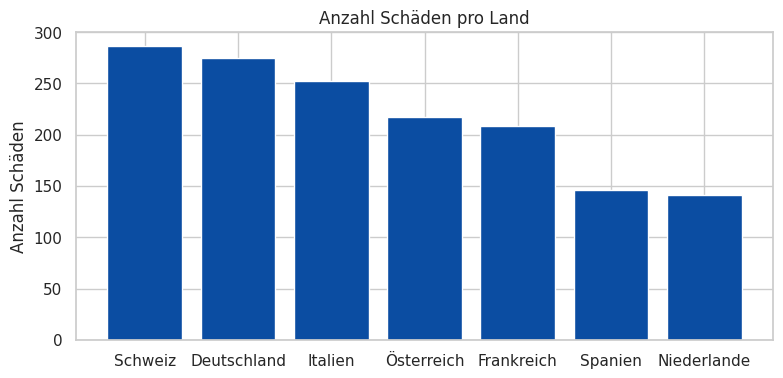

In [31]:
anzahl = schaeden["land"].value_counts()
plt.figure(figsize=(9, 4))
plt.bar(anzahl.index, anzahl.values, color="#0B4DA2")
plt.title("Anzahl Schäden pro Land")
plt.ylabel("Anzahl Schäden")
plt.show()

### 3.2 Schadenaufwand pro Gefahr (seaborn)
Dasselbe mit **seaborn**: weniger Code, schöneres Ergebnis. Wir sortieren nach Aufwand.
👉 Welche Gefahr kostet am meisten, obwohl sie selten ist?

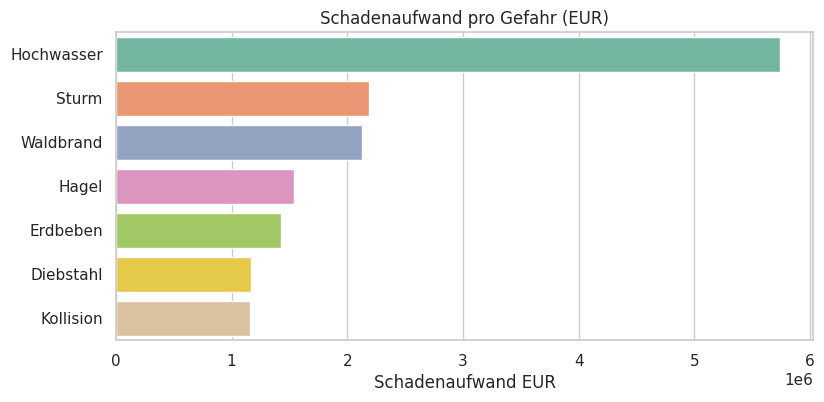

In [32]:
aufwand_gefahr = schaeden.groupby("gefahr")["betrag_eur"].sum().sort_values(ascending=False).reset_index()
plt.figure(figsize=(9, 4))
sns.barplot(data=aufwand_gefahr, x="betrag_eur", y="gefahr", hue="gefahr", legend=False)
plt.title("Schadenaufwand pro Gefahr (EUR)")
plt.xlabel("Schadenaufwand EUR")
plt.ylabel("")
plt.show()

### 3.3 Schadenquote pro Land mit Referenzlinien
Bei **100%** entsprechen die Schäden den Prämien, noch vor sonstigen Kosten.
**70%** ist ein frei gewählter Demo-Zielwert, keine allgemeine Marktregel.

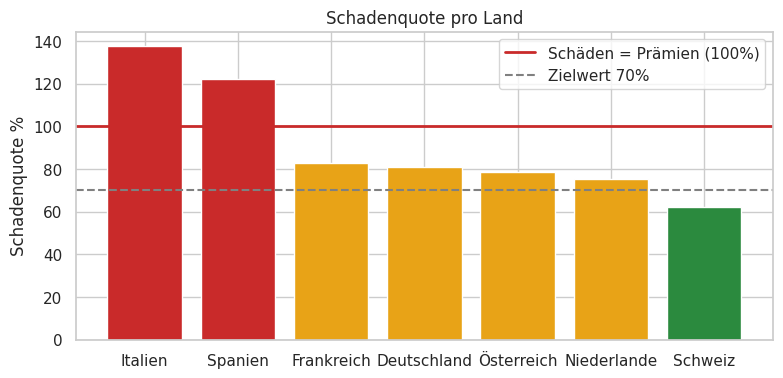

In [33]:
sq = pro_land["schadenquote"].sort_values(ascending=False)
farben = ["#C92A2A" if v > 1 else "#E8A317" if v > 0.7 else "#2B8A3E" for v in sq.values]
plt.figure(figsize=(9, 4))
plt.bar(sq.index, sq.values * 100, color=farben)
plt.axhline(100, color="#C92A2A", linewidth=2, label="Schäden = Prämien (100%)")
plt.axhline(70, color="grey", linestyle="--", label="Zielwert 70%")
plt.title("Schadenquote pro Land")
plt.ylabel("Schadenquote %")
plt.legend()
plt.show()

### 3.4 Entwicklung über die Zeit: Schäden pro Monat
Wir zählen Schäden pro Monat. `dt.to_period("M")` macht aus einem Datum den Monat.
👉 Siehst du die **Sommerspitzen** (Hagel) und die **Winterspitzen** (Sturm)?

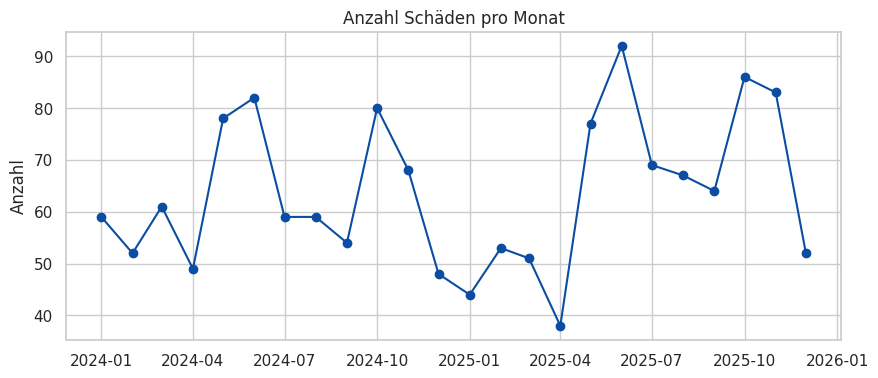

In [34]:
pro_monat = schaeden.groupby(schaeden["datum"].dt.to_period("M")).size()
pro_monat.index = pro_monat.index.to_timestamp()
plt.figure(figsize=(10, 4))
plt.plot(pro_monat.index, pro_monat.values, marker="o", color="#0B4DA2")
plt.title("Anzahl Schäden pro Monat")
plt.ylabel("Anzahl")
plt.show()

### 3.5 Saisonalität pro Gefahr
Mit `hue` zeichnet seaborn eine Linie **pro Gefahr**. So sieht man, welche Gefahr wann zuschlägt.

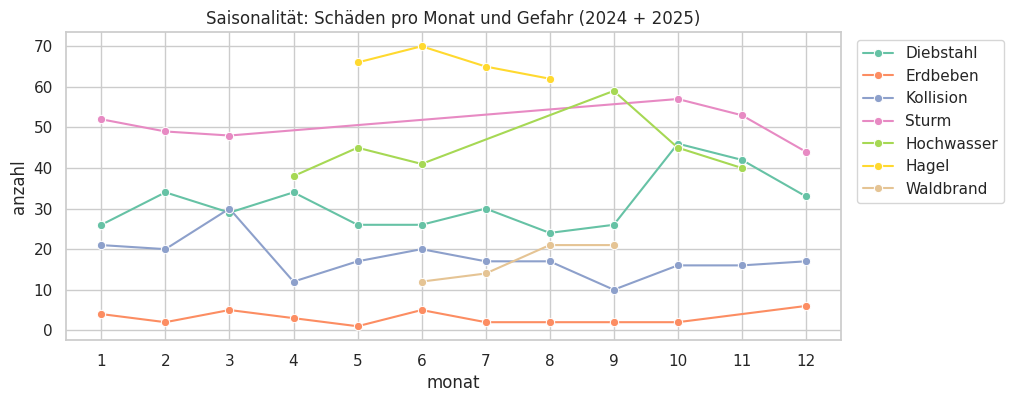

In [35]:
schaeden["monat"] = schaeden["datum"].dt.month
saisonal = schaeden.groupby(["monat", "gefahr"]).size().reset_index(name="anzahl")
plt.figure(figsize=(10, 4))
sns.lineplot(data=saisonal, x="monat", y="anzahl", hue="gefahr", marker="o")
plt.title("Saisonalität: Schäden pro Monat und Gefahr (2024 + 2025)")
plt.xticks(range(1, 13))
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

### 3.6 Verteilung der Schadenbeträge (Histogramm)
Die meisten Schäden sind klein, wenige sehr gross. Das ist typisch für Versicherungen (eine «rechtsschiefe» Verteilung).
Mit einer **logarithmischen Achse** sieht man die Verteilung besser.

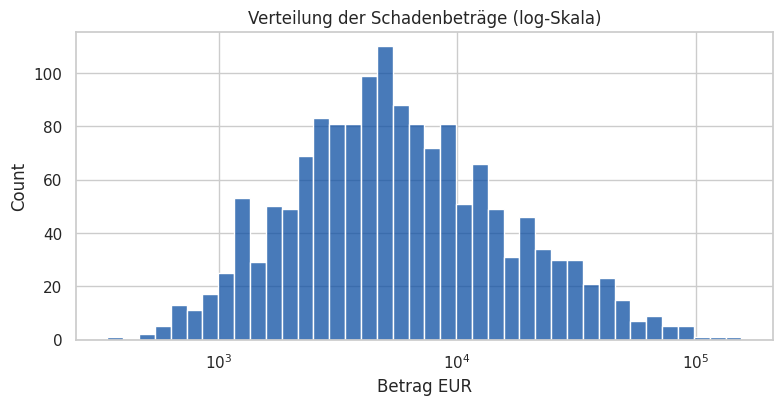

In [36]:
plt.figure(figsize=(9, 4))
sns.histplot(schaeden["betrag_eur"], bins=40, log_scale=True, color="#0B4DA2")
plt.title("Verteilung der Schadenbeträge (log-Skala)")
plt.xlabel("Betrag EUR")
plt.show()

### 3.7 Schadenbeträge pro Gefahr (Boxplot)
Ein **Boxplot** zeigt pro Gruppe Median (Strich), mittlere 50% (Box) und Ausreisser (Punkte).

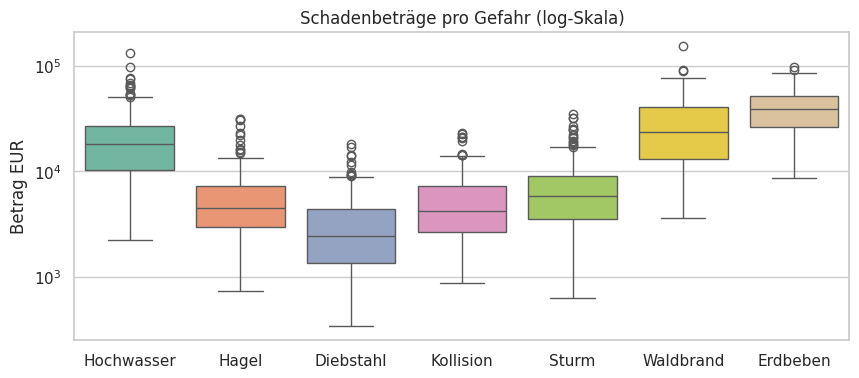

In [37]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=schaeden, x="gefahr", y="betrag_eur", hue="gefahr", legend=False)
plt.yscale("log")
plt.title("Schadenbeträge pro Gefahr (log-Skala)")
plt.xlabel("")
plt.ylabel("Betrag EUR")
plt.show()

### 3.8 Heatmap: Land × Gefahr
Eine **Heatmap** zeigt zwei Dimensionen gleichzeitig. Je dunkler, desto mehr Schäden.
👉 Erkennst du das **Risikoprofil** jedes Landes?

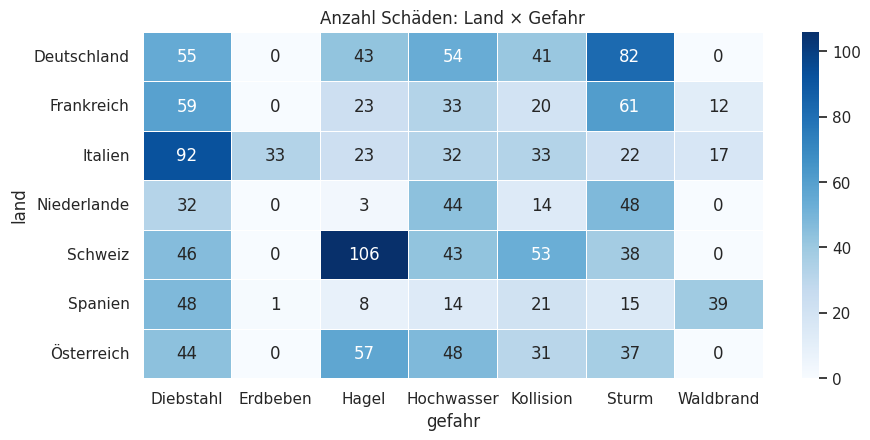

In [38]:
matrix = pd.crosstab(schaeden["land"], schaeden["gefahr"])
plt.figure(figsize=(10, 4.5))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", linewidths=0.5)
plt.title("Anzahl Schäden: Land × Gefahr")
plt.show()

### 3.9 Schäden pro Werkstatt
Wir vergleichen die zehn Dienstleister mit den meisten Schadenfällen.
Ein hoher Wert kann durch viele Kunden oder eine Spezialisierung entstehen.
Er ist **für sich allein kein Betrugsindikator**. Die engere Prüfung folgt
anhand von Gefahr, Zeitraum, Betragsband und verschiedenen Kunden.

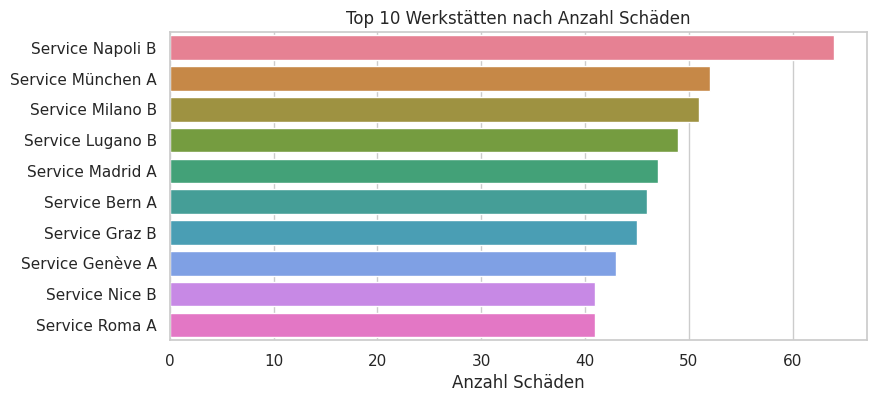

In [39]:
top_w = schaeden["werkstatt_id"].value_counts().head(10).rename_axis("werkstatt_id").reset_index(name="anzahl")
top_w = top_w.merge(werkstaetten[["werkstatt_id", "name"]], on="werkstatt_id")
plt.figure(figsize=(9, 4))
sns.barplot(data=top_w, x="anzahl", y="name", hue="name", legend=False)
plt.title("Top 10 Werkstätten nach Anzahl Schäden")
plt.xlabel("Anzahl Schäden")
plt.ylabel("")
plt.show()

---
# Teil 4 · Geo-Karte mit OpenStreetMap
Wo stehen versicherte Werte, und wo treten Schäden auf?
Wir erstellen eine Folium-Karte mit **Länderebene, Stadtkreisen und Heatmap**.
Die Kartenkacheln stammen von CARTO mit OpenStreetMap-Daten; Ländergrenzen
laden wir aus dem öffentlichen Folium-Beispieldatensatz.
Für diese Darstellung wird Internet benötigt. Die Grenzen sind vereinfacht
und keine amtliche geografische Referenz.

### 4.1 Daten pro Stadt vorbereiten
Für die Karte brauchen wir pro Stadt: Anzahl Schäden, Aufwand, die häufigste Gefahr und die Koordinaten.

In [40]:
pro_stadt = schaeden.groupby("stadt").agg(anzahl=("schaden_id", "count"), aufwand_eur=("betrag_eur", "sum"),
                                          top_gefahr=("gefahr", lambda g: g.value_counts().index[0])).reset_index()
pro_stadt = pro_stadt.merge(staedte, on="stadt")
pro_stadt.head()

,stadt,anzahl,aufwand_eur,top_gefahr,land,iso3,lat,lon
0,Amsterdam,68,735730.0,Hochwasser,Niederlande,NLD,52.3676,4.9041
1,Berlin,58,479650.0,Sturm,Deutschland,DEU,52.5200,13.4050
2,Bern,75,510180.0,Hagel,Schweiz,CHE,46.9480,7.4474
3,Genève,79,600670.0,Hagel,Schweiz,CHE,46.2044,6.1432
4,Graz,83,751250.0,Hagel,Österreich,AUT,47.0707,15.4395


### 4.2 Basiskarte von Europa
`folium.Map` legt Mittelpunkt, Zoomstufe und Hintergrund fest.
Colab stellt die interaktive Karte direkt im Zellenausgabebereich dar.

In [41]:
karte = folium.Map(location=[47.0, 8.0], zoom_start=4, tiles="cartodbpositron")
karte

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


### 4.3 Länder nach Schadenquote einfärben (Choropleth)
Wir laden öffentliche Ländergrenzen als **GeoJSON** und verknüpfen sie über
ISO-Ländercodes mit den Kennzahlen. Grün steht für eine niedrigere, Rot für
eine höhere Schadenquote **innerhalb der dargestellten Daten**.
Die Farbskala ist keine Profitabilitätsbewertung.

In [42]:
import json
from urllib.request import urlopen

geo_url = (
    "https://raw.githubusercontent.com/python-visualization/"
    "folium-example-data/main/world_countries.json"
)
with urlopen(geo_url, timeout=30) as antwort:
    welt = json.load(antwort)
laendercodes = set(staedte["iso3"])
grenzen = {
    "type": "FeatureCollection",
    "features": [f for f in welt["features"] if f["id"] in laendercodes],
}
assert {f["id"] for f in grenzen["features"]} == laendercodes, "Ländergrenzen fehlen."
sq_iso = pro_land.reset_index().merge(
    staedte[["land", "iso3"]].drop_duplicates(), on="land", validate="one_to_one"
)
folium.Choropleth(
    geo_data=grenzen, data=sq_iso, columns=["iso3", "schadenquote"],
    key_on="feature.id", fill_color="RdYlGn_r", fill_opacity=0.55,
    line_opacity=0.3, nan_fill_opacity=0,
    legend_name="Schadenquote (1.0 = 100%)", name="Schadenquote pro Land",
).add_to(karte)
karte

### 4.4 Kreise pro Stadt: Grösse = Schadenaufwand
Jede Stadt bekommt einen Kreis. **Je grösser der Kreis, desto höher der Schadenaufwand.** Klicke auf einen Kreis für Details.

In [43]:
staedte_layer = folium.FeatureGroup(name="Schäden pro Stadt")
for _, s in pro_stadt.iterrows():
    folium.CircleMarker(location=[s["lat"], s["lon"]], radius=4 + s["aufwand_eur"] / 400000,
                        color="#0B4DA2", fill=True, fill_opacity=0.6,
                        popup=f"<b>{s['stadt']}</b><br>{s['anzahl']} Schäden<br>EUR {s['aufwand_eur']:,.0f}<br>Top-Gefahr: {s['top_gefahr']}",
                        tooltip=s["stadt"]).add_to(staedte_layer)
staedte_layer.add_to(karte)
karte

### 4.5 Heatmap der Naturgefahren
Wir verteilen die Schäden zufällig um die Stadtzentren. Diese Positionen sind
**nur eine Visualisierung**, keine echten Schadenorte.
Die Heatmap zeigt die **Häufigkeit**, nicht die Schadenhöhe.

In [44]:
natcat = schaeden[schaeden["gefahr"].isin(["Hagel", "Sturm", "Hochwasser", "Erdbeben", "Waldbrand"])].merge(staedte[["stadt", "lat", "lon"]], on="stadt")
punkte = np.column_stack([natcat["lat"] + rng.normal(0, 0.15, len(natcat)), natcat["lon"] + rng.normal(0, 0.15, len(natcat))]).tolist()
HeatMap(punkte, radius=14, blur=18, name="Heatmap Naturgefahren").add_to(karte)
karte

### 4.6 Ebenen-Steuerung hinzufügen
Oben rechts erscheint ein Menü. Damit kannst du die Schichten **ein- und ausschalten**.

In [45]:
folium.LayerControl(collapsed=False).add_to(karte)
karte

### 4.7 Karte als HTML-Datei speichern (optional)
Die Karte kann als eigenständige Webseite gespeichert und z.B. per E-Mail geteilt werden. In Colab findest du die Datei links im **Ordner-Symbol** 📁.

In [46]:
karte.save("rigi_schadenkarte.html")
print("Gespeichert: rigi_schadenkarte.html")

Gespeichert: rigi_schadenkarte.html


---
# Teil 5 · Aus Daten wird Kontext: eine Ontologie in RDF
Diagramme zeigen Muster, erklären aber noch nicht die Bedeutung unserer Begriffe.
Eine **Ontologie** beschreibt Klassen, Beziehungen und Eigenschaften so,
dass Menschen und Programme dieselben fachlichen Begriffe verwenden können.

| Baustein | Bedeutung | Beispiel |
|---|---|---|
| Klasse | eine Art von Ding | `Kunde`, `Police`, `Schaden` |
| Beziehung / Object Property | Verbindung zwischen Dingen | Kunde **hatPolice** Police |
| Eigenschaft / Data Property | typisierter Wert | Schaden **hatBetrag** 4'500 |
| Instanz | ein konkretes Ding | Kunde `K1001` |

Ein RDF-**Tripel** besteht aus **Subjekt → Prädikat → Objekt**.
Die Ontologie ist das **Schema**; die konkreten Daten bilden die Instanzen
im **Wissensgraphen**. Beides zusammen liefert später den Agentenkontext.

```text
Kunde ──hatPolice──▶ Police ──hatSchaden──▶ Schaden ──verursachtDurch──▶ Gefahr
  │                                        │
  └──wohntIn──▶ Stadt ──liegtIn──▶ Land     └──repariertVon──▶ Werkstatt
                    ▲                                           │
                    └────────────────ansaessigIn──────────────────┘
```

**Wichtig:** RDF/OWL macht fehlende Fakten nicht automatisch wahr oder falsch.
`rdflib` führt allein keinen vollständigen OWL-Reasoner aus. Hierarchien fragen
wir ausdrücklich mit SPARQL-Pfaden ab. Domain und Range sind semantische
Aussagen, keine Datenvalidierung; die Beziehungen wurden deshalb bereits in
Teil 2 geprüft.

### 5.1 Leeren Wissensgraphen und Namensraum anlegen
`INS` ist unser eigener Namensraum. Jeder Begriff bekommt eine eindeutige Adresse, z.B. `http://rigi.example/insurance#Kunde`.

In [47]:
g = Graph()
INS = Namespace("http://rigi.example/insurance#")
g.bind("ins", INS)
print("Leerer Graph mit", len(g), "Tripeln")

Leerer Graph mit 0 Tripeln


### 5.2 Klassen definieren
Wir definieren 7 Klassen. Jede Zeile erzeugt das Tripel «X ist eine Klasse» (`rdf:type owl:Class`) und einen lesbaren Namen (`rdfs:label`).

In [48]:
klassen = ["Kunde", "Police", "Schaden", "Gefahr", "Werkstatt", "Stadt", "Land"]
for k in klassen:
    g.add((INS[k], RDF.type, OWL.Class))
    g.add((INS[k], RDFS.label, Literal(k, lang="de")))
print("Klassen definiert:", klassen)

Klassen definiert: ['Kunde', 'Police', 'Schaden', 'Gefahr', 'Werkstatt', 'Stadt', 'Land']


### 5.3 Unterklassen: Gefahren gruppieren
`Naturgefahr` und `SonstigeGefahr` sind Unterklassen von `Gefahr`.
Später traversiert SPARQL mit `rdfs:subClassOf*` diese Hierarchie explizit.
So können wir Oberbegriffe abfragen, ohne auf automatische Inferenz zu vertrauen.

In [49]:
g.add((INS.Naturgefahr, RDF.type, OWL.Class))
g.add((INS.Naturgefahr, RDFS.subClassOf, INS.Gefahr))
g.add((INS.SonstigeGefahr, RDF.type, OWL.Class))
g.add((INS.SonstigeGefahr, RDFS.subClassOf, INS.Gefahr))
print("Hierarchie: Naturgefahr ⊂ Gefahr, SonstigeGefahr ⊂ Gefahr")

Hierarchie: Naturgefahr ⊂ Gefahr, SonstigeGefahr ⊂ Gefahr


### 5.4 Beziehungen definieren (Object Properties)
Jede Beziehung hat eine **Domain** (von welcher Klasse sie ausgeht) und eine **Range** (auf welche Klasse sie zeigt).

In [50]:
beziehungen = [("hatPolice", "Kunde", "Police"), ("hatSchaden", "Police", "Schaden"),
               ("verursachtDurch", "Schaden", "Gefahr"), ("repariertVon", "Schaden", "Werkstatt"),
               ("wohntIn", "Kunde", "Stadt"), ("liegtIn", "Stadt", "Land"), ("ansaessigIn", "Werkstatt", "Stadt")]
for name, von, nach in beziehungen:
    g.add((INS[name], RDF.type, OWL.ObjectProperty))
    g.add((INS[name], RDFS.domain, INS[von]))
    g.add((INS[name], RDFS.range, INS[nach]))
pd.DataFrame(beziehungen, columns=["Beziehung", "von (Domain)", "nach (Range)"])

,Beziehung,von (Domain),nach (Range)
0,hatPolice,Kunde,Police
1,hatSchaden,Police,Schaden
2,verursachtDurch,Schaden,Gefahr
3,repariertVon,Schaden,Werkstatt
4,wohntIn,Kunde,Stadt
5,liegtIn,Stadt,Land
6,ansaessigIn,Werkstatt,Stadt


### 5.5 Eigenschaften mit Werten definieren (Data Properties)
Diese Eigenschaften speichern **Zahlen oder Texte**, z.B. den Schadenbetrag.

In [51]:
for name, klasse, typ in [("hatBetrag", "Schaden", XSD.decimal), ("hatDatum", "Schaden", XSD.date),
                          ("hatPraemie", "Police", XSD.decimal), ("hatSparte", "Police", XSD.string),
                          ("hatSegment", "Kunde", XSD.string)]:
    g.add((INS[name], RDF.type, OWL.DatatypeProperty))
    g.add((INS[name], RDFS.domain, INS[klasse]))
    g.add((INS[name], RDFS.range, typ))
print("Schema fertig. Tripel bisher:", len(g))

Schema fertig. Tripel bisher: 54


### 5.6 Das Schema als Text anzeigen (Turtle-Format)
**Turtle** ist ein lesbares Standardformat für RDF. Wir zeigen einen Ausschnitt.
Das vollständige Modell kann z.B. mit rdflib oder Protégé gelesen werden.
Andere Plattformen benötigen gegebenenfalls eine eigene Importschnittstelle.

In [53]:
print(g.serialize(format="turtle")[:1500])

@prefix ins: <http://rigi.example/insurance#> .
@prefix owl: <http://www.w3.org/2002/07/owl#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

ins:Naturgefahr a owl:Class ;
    rdfs:subClassOf ins:Gefahr .

ins:SonstigeGefahr a owl:Class ;
    rdfs:subClassOf ins:Gefahr .

ins:ansaessigIn a owl:ObjectProperty ;
    rdfs:domain ins:Werkstatt ;
    rdfs:range ins:Stadt .

ins:hatBetrag a owl:DatatypeProperty ;
    rdfs:domain ins:Schaden ;
    rdfs:range xsd:decimal .

ins:hatDatum a owl:DatatypeProperty ;
    rdfs:domain ins:Schaden ;
    rdfs:range xsd:date .

ins:hatPolice a owl:ObjectProperty ;
    rdfs:domain ins:Kunde ;
    rdfs:range ins:Police .

ins:hatPraemie a owl:DatatypeProperty ;
    rdfs:domain ins:Police ;
    rdfs:range xsd:decimal .

ins:hatSchaden a owl:ObjectProperty ;
    rdfs:domain ins:Police ;
    rdfs:range ins:Schaden .

ins:hatSegment a owl:DatatypeProperty ;
    rdfs:domain ins:Kunde ;
    rdfs:range

### 5.7 Länder, Städte und Gefahren als Instanzen einfügen
Jetzt füllen wir das Schema mit **konkreten synthetischen Instanzen**.
Gefahren erhalten einen Typ aus der passenden Unterklasse.

In [54]:
for land in staedte["land"].unique():
    g.add((INS[land], RDF.type, INS.Land))
for _, s in staedte.iterrows():
    g.add((INS[s["stadt"]], RDF.type, INS.Stadt))
    g.add((INS[s["stadt"]], INS.liegtIn, INS[s["land"]]))
for gef in schaeden["gefahr"].unique():
    klasse = INS.Naturgefahr if gef in ["Hagel", "Sturm", "Hochwasser", "Erdbeben", "Waldbrand"] else INS.SonstigeGefahr
    g.add((INS[gef], RDF.type, klasse))
print("Tripel bisher:", len(g))

Tripel bisher: 110


### 5.8 Kunden, Policen, Schäden und Werkstätten einfügen
Für jede Zeile in unseren Tabellen erzeugen wir Tripel. Das ist der Schritt von der **Tabelle zum Graphen**.
⏱ Dauert ein paar Sekunden.

In [55]:
for _, k in kunden.iterrows():
    g.add((INS[k["kunde_id"]], RDF.type, INS.Kunde))
    g.add((INS[k["kunde_id"]], INS.wohntIn, INS[k["stadt"]]))
    g.add((INS[k["kunde_id"]], INS.hatSegment, Literal(k["segment"])))
for _, p in policen.iterrows():
    g.add((INS[p["police_id"]], RDF.type, INS.Police))
    g.add((INS[p["kunde_id"]], INS.hatPolice, INS[p["police_id"]]))
    g.add((INS[p["police_id"]], INS.hatSparte, Literal(p["sparte"])))
    g.add((INS[p["police_id"]], INS.hatPraemie, Literal(p["praemie_eur"], datatype=XSD.decimal)))
for _, w in werkstaetten.iterrows():
    g.add((INS[w["werkstatt_id"]], RDF.type, INS.Werkstatt))
    g.add((INS[w["werkstatt_id"]], RDFS.label, Literal(w["name"])))
    g.add((INS[w["werkstatt_id"]], INS.ansaessigIn, INS[w["stadt"]]))
for _, s in schaeden.iterrows():
    g.add((INS[s["schaden_id"]], RDF.type, INS.Schaden))
    g.add((INS[s["police_id"]], INS.hatSchaden, INS[s["schaden_id"]]))
    g.add((INS[s["schaden_id"]], INS.verursachtDurch, INS[s["gefahr"]]))
    g.add((INS[s["schaden_id"]], INS.repariertVon, INS[s["werkstatt_id"]]))
    g.add((INS[s["schaden_id"]], INS.hatBetrag, Literal(s["betrag_eur"], datatype=XSD.decimal)))
    g.add((INS[s["schaden_id"]], INS.hatDatum, Literal(s["datum"].date(), datatype=XSD.date)))
print("Wissensgraph fertig: ", len(g), "Tripel")

Wissensgraph fertig:  53386 Tripel


### 5.9 Ein paar Tripel ansehen
So sieht das Wissen über einen einzelnen Schaden aus: **Subjekt → Prädikat → Objekt**.

In [56]:
for s, p, o in g.triples((INS.S50000, None, None)):
    print(s.split("#")[-1], " →", p.split("#")[-1], " →", str(o).split("#")[-1])

S50000  → type  → Schaden
S50000  → verursachtDurch  → Hochwasser
S50000  → repariertVon  → W12A
S50000  → hatBetrag  → 14920.0
S50000  → hatDatum  → 2024-10-01


### 5.10 Fragen an den RDF-Kontext: SPARQL
**SPARQL** ist die Abfragesprache für Wissensgraphen.
**Frage 1:** Wie viele Schäden und welcher Aufwand pro Naturgefahr?
Der Pfad `rdfs:subClassOf*` berücksichtigt auch Unterklassen von `Naturgefahr`.

In [57]:
abfrage1 = '''
PREFIX ins: <http://rigi.example/insurance#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
SELECT ?gefahr (COUNT(DISTINCT ?s) AS ?anzahl) (SUM(?b) AS ?aufwand)
WHERE {
  ?s ins:verursachtDurch ?g ; ins:hatBetrag ?b .
  ?g a ?klasse .
  ?klasse rdfs:subClassOf* ins:Naturgefahr .
  BIND(STRAFTER(STR(?g), "#") AS ?gefahr)
}
GROUP BY ?gefahr ORDER BY DESC(?aufwand)
'''
naturgefahren_rdf = pd.DataFrame(
    [(str(r.gefahr), int(r.anzahl), float(r.aufwand)) for r in g.query(abfrage1)],
    columns=["Naturgefahr", "Anzahl", "Aufwand EUR"],
)
naturgefahren_rdf.round(0)

,Naturgefahr,Anzahl,Aufwand EUR
0,Hochwasser,268,5743380.0
1,Sturm,303,2189110.0
2,Waldbrand,68,2125000.0
3,Hagel,263,1537520.0
4,Erdbeben,34,1424480.0


### 5.11 SPARQL Frage 2: Hagelschäden in der Schweiz
Hier verbinden wir **4 Beziehungen** in einer Abfrage: Schaden → Police → Kunde → Stadt → Land.
In einer Tabellenwelt wären das mehrere Joins.

In [58]:
abfrage2 = '''
PREFIX ins: <http://rigi.example/insurance#>
SELECT ?stadt (COUNT(?s) AS ?anzahl) (SUM(?b) AS ?aufwand)
WHERE {
  ?s ins:verursachtDurch ins:Hagel ; ins:hatBetrag ?b .
  ?p ins:hatSchaden ?s .
  ?k ins:hatPolice ?p ; ins:wohntIn ?st .
  ?st ins:liegtIn ins:Schweiz .
  BIND(STRAFTER(STR(?st), "#") AS ?stadt)
}
GROUP BY ?stadt ORDER BY DESC(?aufwand)
'''
pd.DataFrame([(str(r.stadt), int(r.anzahl), round(float(r.aufwand))) for r in g.query(abfrage2)],
             columns=["Stadt (CH)", "Hagelschäden", "Aufwand EUR"])

,Stadt (CH),Hagelschäden,Aufwand EUR
0,Genève,28,190080
1,Bern,29,158670
2,Lugano,29,122510
3,Zürich,20,120990


### 5.12 SPARQL Frage 3: Diebstahlschäden nach Dienstleister
Wir zählen verschiedene Kunden, Schadenfälle und den Durchschnittsbetrag.
Diese Rangliste dient der Exploration, nicht einer Betrugsfeststellung.
Eine nachvollziehbare Prüfregel mit Zeitfenster folgt in Teil 7.

In [59]:
abfrage3 = '''
PREFIX ins: <http://rigi.example/insurance#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
SELECT ?name (COUNT(DISTINCT ?k) AS ?kunden) (COUNT(?s) AS ?schaeden) (AVG(?b) AS ?avg)
WHERE {
  ?s ins:repariertVon ?w ; ins:verursachtDurch ins:Diebstahl ; ins:hatBetrag ?b .
  ?w rdfs:label ?name .
  ?p ins:hatSchaden ?s . ?k ins:hatPolice ?p .
}
GROUP BY ?name ORDER BY DESC(?schaeden) LIMIT 5
'''
pd.DataFrame([(str(r.name), int(r.kunden), int(r.schaeden), round(float(r["avg"]))) for r in g.query(abfrage3)],
             columns=["Werkstatt", "versch. Kunden", "Diebstahl-Schäden", "Ø Betrag EUR"])

,Werkstatt,versch. Kunden,Diebstahl-Schäden,Ø Betrag EUR
0,Service Napoli B,17,38,4073
1,Service Valencia B,16,16,3359
2,Service Milano B,15,15,3160
3,Service Madrid A,13,14,2032
4,Service Roma A,12,13,2888


### 5.13 Ontologie als Datei speichern (optional)
Die Ontologie mit allen Daten wird als `.ttl`-Datei gespeichert. Man kann sie z.B. im kostenlosen Tool **Protégé** öffnen.

In [60]:
g.serialize("rigi_insurance_ontologie.ttl", format="turtle")
print("Gespeichert: rigi_insurance_ontologie.ttl")

Gespeichert: rigi_insurance_ontologie.ttl


---
# Teil 6 · Den Wissensgraphen visualisieren
Wir machen Zusammenhänge sichtbar:
1. das Ontologie-Schema als statisches Bild,
2. einen interaktiven Ausschnitt mit Kunden, Policen, Schäden und Dienstleistern,
3. eine explorative Analyse des eingebauten Musters.

Der Netzwerkausschnitt wird zur Veranschaulichung aus denselben Tabellen
aufgebaut. **Der Agent in Teil 7 nutzt dagegen ausschliesslich den RDF-Graphen**,
nicht diese Tabellen oder die zuvor markierte Werkstatt.

### 6.1 Das Schema als Graph (networkx + matplotlib)
Wir zeichnen nur die **Klassen** und ihre **Beziehungen**. Das ist die «Landkarte» unseres Wissens.

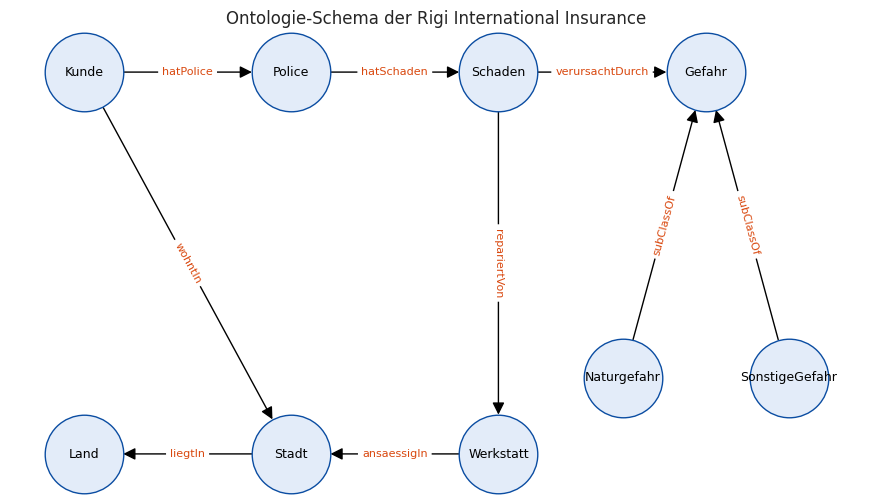

In [62]:
schema = nx.DiGraph()
for name, von, nach in beziehungen:
    schema.add_edge(von, nach, label=name)
schema.add_edge("Naturgefahr", "Gefahr", label="subClassOf")
schema.add_edge("SonstigeGefahr", "Gefahr", label="subClassOf")
pos = {"Kunde": (0, 1), "Police": (2, 1), "Schaden": (4, 1), "Gefahr": (6, 1),
       "Naturgefahr": (5.2, -0.6), "SonstigeGefahr": (6.8, -0.6),
       "Land": (0, -1), "Stadt": (2, -1), "Werkstatt": (4, -1)}   # feste Positionen für ein lesbares Bild
plt.figure(figsize=(11, 6))
nx.draw_networkx(schema, pos, node_size=3200, node_color="#E3ECF9", edgecolors="#0B4DA2", font_size=9, arrowsize=18)
nx.draw_networkx_edge_labels(schema, pos, edge_labels=nx.get_edge_attributes(schema, "label"), font_size=8, font_color="#D9480F")
plt.title("Ontologie-Schema der Rigi International Insurance")
plt.axis("off")
plt.show()

### 6.2 Ausschnitt für die interaktive Grafik wählen
Der ganze Graph hat tausende Knoten, das wäre unübersichtlich. Wir nehmen einen spannenden **Ausschnitt**:
alle **Diebstahl-Schäden in Napoli** und **Roma** (Italien), mit Kunden, Policen und Werkstätten.

In [63]:
auswahl = schaeden[(schaeden["gefahr"] == "Diebstahl") & (schaeden["stadt"].isin(["Napoli", "Roma"]))]
print("Schäden im Ausschnitt:", len(auswahl))
auswahl.head()

Schäden im Ausschnitt: 69


,schaden_id,police_id,kunde_id,land,stadt,sparte,gefahr,datum,betrag_eur,werkstatt_id,monat
84,S50084,P24136,K4416,Italien,Roma,Gebäude,Diebstahl,2024-06-21,3360.0,W12B,6
88,S50088,P27675,K2884,Italien,Roma,Motorfahrzeug,Diebstahl,2024-09-07,1820.0,W12B,9
130,S50130,P24660,K2195,Italien,Napoli,Gebäude,Diebstahl,2025-06-08,4430.0,W13A,6
201,S50201,P25607,K1849,Italien,Roma,Gebäude,Diebstahl,2024-09-03,4270.0,W12B,9
213,S50213,P21033,K3926,Italien,Roma,Gebäude,Diebstahl,2025-06-18,1270.0,W12A,6


### 6.3 Den Graphen mit networkx aufbauen
Jeder Knoten bekommt einen **Typ** (für die Farbe). Jede Kante bekommt die **Beziehung** als Namen.

In [64]:
G = nx.Graph()
for _, s in auswahl.iterrows():
    w_name = werkstaetten.set_index("werkstatt_id").loc[s["werkstatt_id"], "name"]
    G.add_node(s["kunde_id"], typ="Kunde")
    G.add_node(s["police_id"], typ="Police")
    G.add_node(s["schaden_id"], typ="Schaden", betrag=s["betrag_eur"])
    G.add_node(w_name, typ="Werkstatt")
    G.add_node(s["stadt"], typ="Stadt")
    G.add_edge(s["kunde_id"], s["police_id"], label="hatPolice")
    G.add_edge(s["police_id"], s["schaden_id"], label="hatSchaden")
    G.add_edge(s["schaden_id"], w_name, label="repariertVon")
    G.add_edge(s["kunde_id"], s["stadt"], label="wohntIn")
print("Knoten:", G.number_of_nodes(), " Kanten:", G.number_of_edges())

Knoten: 171  Kanten: 234


### 6.4 Interaktive Visualisierung mit pyvis 🎨
Farben: 🔵 Kunde · 🟢 Police · 🔴 Schaden · 🟠 Werkstatt · 🟣 Stadt
- **Ziehe** Knoten mit der Maus, **zoome** mit dem Mausrad, **fahre** über einen Knoten für Details.
- 👉 Welche Werkstatt ist mit auffällig vielen Schäden verbunden?

In [65]:
farben = {"Kunde": "#4C8BF5", "Police": "#20A39E", "Schaden": "#E5576B", "Werkstatt": "#E8A317", "Stadt": "#8E6CEF"}
net = Network(height="600px", width="100%", bgcolor="#ffffff", notebook=True, cdn_resources="in_line")
for n, d in G.nodes(data=True):
    groesse = 35 if d["typ"] == "Werkstatt" else 30 if d["typ"] == "Stadt" else 12
    titel = f"{d['typ']}: {n}" + (f" · EUR {d['betrag']:,.0f}" if "betrag" in d else "")
    net.add_node(n, label=n if d["typ"] in ["Werkstatt", "Stadt"] else "", title=titel, color=farben[d["typ"]], size=groesse)
for a, b, d in G.edges(data=True):
    net.add_edge(a, b, title=d["label"], color="#C0C8D6")
net.force_atlas_2based(gravity=-40, spring_length=80)
from html import escape
graph_html = net.generate_html()
with open("rigi_wissensgraph.html", "w", encoding="utf-8") as datei:
    datei.write(graph_html)
display(HTML(
    '<iframe title="Rigi Wissensgraph" style="width:100%;height:620px;border:0" '
    'sandbox="allow-scripts allow-same-origin" srcdoc="'
    + escape(graph_html, quote=True) + '"></iframe>'
))

/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


### 6.5 Graph-Analyse: Wer ist am stärksten vernetzt?
**Degree Centrality** misst Verbindungen im gewählten Ausschnitt.
Hohe Zentralität beschreibt hier vor allem eine hohe Fallzahl.
Ohne Vergleichsgruppe, Kundenvolumen und weitere Fakten ist das **kein Beweis
und keine kalibrierte Betrugswahrscheinlichkeit**.

In [66]:
zentral = nx.degree_centrality(G)
werkstatt_zentral = {n: round(c, 3) for n, c in zentral.items() if G.nodes[n]["typ"] == "Werkstatt"}
pd.Series(werkstatt_zentral, name="Zentralität").sort_values(ascending=False)

,Zentralität
Service Napoli B,0.224
Service Roma A,0.076
Service Roma B,0.059
Service Napoli A,0.047


### 6.6 Das eingebaute Muster genauer ansehen
Für die didaktische Kontrolle betrachten wir die bekannte Werkstatt und
Diebstahlschäden im Zeitraum **1. Oktober bis vor 1. Dezember 2025**.
Der Agent wird später **alle Werkstätten** prüfen, ohne diesen Namen zu kennen.

In [67]:
verdacht = schaeden.loc[
    (schaeden["werkstatt_id"] == werkstatt_napoli_b)
    & (schaeden["gefahr"] == "Diebstahl")
    & (schaeden["datum"] >= "2025-10-01")
    & (schaeden["datum"] < "2025-12-01")
]
print(
    "Schäden:", len(verdacht), "| verschiedene Kunden:", verdacht["kunde_id"].nunique(),
    "| Ø Betrag: EUR", round(verdacht["betrag_eur"].mean()),
    "| Zeitraum:", verdacht["datum"].min().date(), "bis", verdacht["datum"].max().date(),
)

Schäden: 25 | verschiedene Kunden: 8 | Ø Betrag: EUR 4839 | Zeitraum: 2025-10-01 bis 2025-11-28


### 6.7 Vergleich als Grafik: auffällige Werkstatt vs. alle anderen
Ein **Streudiagramm** der Diebstahl-Schäden: Datum gegen Betrag. Die Werkstatt «Service Napoli B» ist rot markiert.
👉 Siehst du die Häufung knapp unter EUR 5'000?

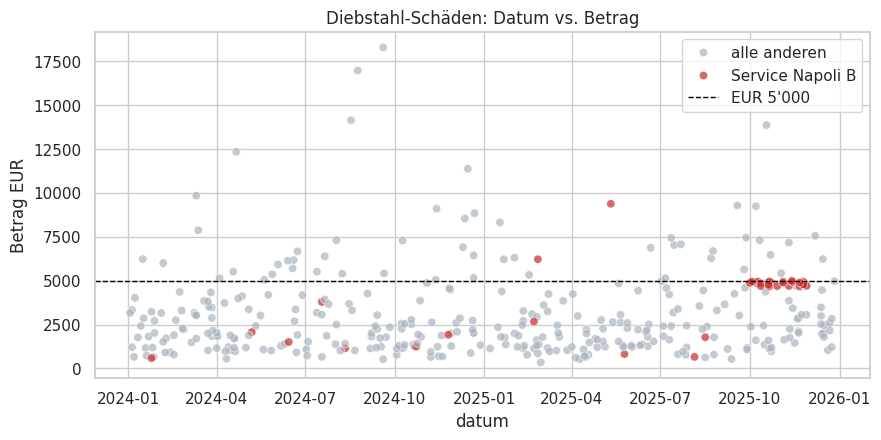

In [68]:
dieb = schaeden[schaeden["gefahr"] == "Diebstahl"].copy()
dieb["werkstatt"] = np.where(dieb["werkstatt_id"] == werkstatt_napoli_b, "Service Napoli B", "alle anderen")
plt.figure(figsize=(10, 4.5))
sns.scatterplot(data=dieb, x="datum", y="betrag_eur", hue="werkstatt", palette={"alle anderen": "#AAB4C0", "Service Napoli B": "#C92A2A"}, alpha=0.7)
plt.axhline(5000, color="black", linestyle="--", linewidth=1, label="EUR 5'000")
plt.title("Diebstahl-Schäden: Datum vs. Betrag")
plt.ylabel("Betrag EUR")
plt.legend()
plt.show()

---
# Teil 7 · Einen Agenten simulieren, der den RDF-Kontext nutzt
Bisher hat ein Mensch Tabellen und Abfragen ausgewählt. Jetzt simulieren wir
einen kleinen **lesenden Analyse-Agenten**:

**Frage → Absicht erkennen → Kontext laden → SPARQL-Werkzeug aufrufen
→ Befunde mit Belegen formulieren → Grenze oder nächsten Prüfschritt nennen.**

Die Absichtserkennung und Textausgabe sind bewusst regelbasiert, nicht generativ.
Es gibt keine freie SPARQL-Erzeugung, keine API-Aufrufe und keine Schreibaktionen.
Unterstützt werden Fragen nach **Naturgefahren** und nach
**auffälligen Werkstätten/Dienstleistern**.

## 7.1 Fachregeln gehören in den Kontext, nicht in eine versteckte Antwort
Wir ergänzen eine **offengelegte Demo-Prüfregel** als RDF-Instanz:
mindestens 10 Diebstahlschäden von mindestens 5 verschiedenen Kunden bei
demselben Dienstleister, vom 1. Oktober bis vor 1. Dezember 2025,
mit Beträgen von EUR 4'600 bis **unter** EUR 5'000.

Das ist keine validierte Betrugserkennung. Die Regel erzeugt nur einen
**menschlich zu prüfenden Hinweis**. Der Agent liest Schwellen und Zeitraum
später tatsächlich aus RDF.

In [69]:
g.add((INS.Pruefregel, RDF.type, OWL.Class))
g.add((INS.Pruefregel, RDFS.label, Literal("Didaktische Prüfregel", lang="de")))
regel = INS.Regel_Diebstahlhaeufung
g.add((regel, RDF.type, INS.Pruefregel))
g.add((regel, RDFS.label, Literal("Diebstahlhäufung im Betragsband", lang="de")))
g.add((INS.prueftGefahr, RDF.type, OWL.ObjectProperty))
g.add((INS.prueftGefahr, RDFS.domain, INS.Pruefregel))
g.add((INS.prueftGefahr, RDFS.range, INS.Gefahr))
g.add((regel, INS.prueftGefahr, INS.Diebstahl))
for eigenschaft, wert, typ in [
    ("minFaelle", 10, XSD.integer), ("minKunden", 5, XSD.integer),
    ("betragVon", "4600.00", XSD.decimal), ("betragUnter", "5000.00", XSD.decimal),
    ("datumVon", "2025-10-01", XSD.date), ("datumBisExklusiv", "2025-12-01", XSD.date),
]:
    g.add((INS[eigenschaft], RDF.type, OWL.DatatypeProperty))
    g.add((INS[eigenschaft], RDFS.domain, INS.Pruefregel))
    g.add((INS[eigenschaft], RDFS.range, typ))
    g.add((regel, INS[eigenschaft], Literal(wert, datatype=typ)))
g.add((
    regel, RDFS.comment,
    Literal("Nur ein Prüfhinweis; keine automatische Betrugsentscheidung.", lang="de"),
))
print(g.serialize(format="turtle")[-1200:])

 a ins:Stadt ;
    ins:liegtIn ins:Deutschland .

ins:Innsbruck a ins:Stadt ;
    ins:liegtIn ins:Österreich .

ins:Bern a ins:Stadt ;
    ins:liegtIn ins:Schweiz .

ins:Wien a ins:Stadt ;
    ins:liegtIn ins:Österreich .

ins:Napoli a ins:Stadt ;
    ins:liegtIn ins:Italien .

ins:Madrid a ins:Stadt ;
    ins:liegtIn ins:Spanien .

ins:Hamburg a ins:Stadt ;
    ins:liegtIn ins:Deutschland .

ins:Milano a ins:Stadt ;
    ins:liegtIn ins:Italien .

ins:Amsterdam a ins:Stadt ;
    ins:liegtIn ins:Niederlande .

ins:Rotterdam a ins:Stadt ;
    ins:liegtIn ins:Niederlande .

ins:Lugano a ins:Stadt ;
    ins:liegtIn ins:Schweiz .

ins:Lyon a ins:Stadt ;
    ins:liegtIn ins:Frankreich .

ins:Nice a ins:Stadt ;
    ins:liegtIn ins:Frankreich .

ins:Genève a ins:Stadt ;
    ins:liegtIn ins:Schweiz .

ins:Kollision a ins:SonstigeGefahr .

ins:Graz a ins:Stadt ;
    ins:liegtIn ins:Österreich .

ins:Hagel a ins:Naturgefahr .

ins:Hochwasser a ins:Naturgefahr .

ins:Sturm a ins:Naturgefahr .

ins

### 7.2 Kontext sichtbar machen
Eine Ontologie wirkt nicht allein dadurch, dass sie irgendwo gespeichert ist.
Der Agent muss sie **abrufen und verwenden**. Diese Abfrage zeigt die
Prüfregel mit ihren maschinenlesbaren Parametern. Fehlt Kontext, antwortet der
Agent später mit einer **Kontextlücke**, statt Zahlen zu erfinden.

In [70]:
PREFIXE = '''
PREFIX ins: <http://rigi.example/insurance#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
'''
REGEL_ABFRAGE = PREFIXE + '''
SELECT ?regel ?gefahr ?minFaelle ?minKunden ?betragVon ?betragUnter ?von ?bis
WHERE {
  ?regel a ins:Pruefregel ;
    ins:prueftGefahr ?gefahr ;
    ins:minFaelle ?minFaelle ; ins:minKunden ?minKunden ;
    ins:betragVon ?betragVon ; ins:betragUnter ?betragUnter ;
    ins:datumVon ?von ; ins:datumBisExklusiv ?bis .
}
'''
regeln = list(g.query(REGEL_ABFRAGE))
display(pd.DataFrame(
    [[str(wert) for wert in zeile] for zeile in regeln],
    columns=["Regel", "Gefahr", "min. Fälle", "min. Kunden",
             "EUR von", "EUR unter", "Datum von", "Datum bis (exkl.)"],
))

,Regel,Gefahr,min. Fälle,min. Kunden,EUR von,EUR unter,Datum von,Datum bis (exkl.)
0,http://rigi.example/insurance#Regel_Diebstahlh...,http://rigi.example/insurance#Diebstahl,10,5,4600.00,5000.00,2025-10-01,2025-12-01


### 7.3 Zwei begrenzte, lesende Werkzeuge
Der Agent bekommt nur einen `rdflib.Graph` übergeben. Er hat **keinen Zugriff
auf die DataFrames** und nutzt ausschliesslich feste SPARQL-Abfragen.
Parameter werden als RDF-Terme gebunden, nicht in Abfragetext eingesetzt.

- `naturgefahren`: aggregiert Schadenaufwand über die Ontologie-Hierarchie.
- `werkstattpruefung`: liest die Regel, prüft alle Dienstleister und liefert
  die IDs aller passenden Schäden als Belege.

Auch «kein passender Fall» ist etwas anderes als «Kontext fehlt».
RDF ist offen; aus fehlenden Daten folgt keine Entwarnung.

In [71]:
from decimal import Decimal

NATURGEFAHREN_WERKZEUG = PREFIXE + '''
SELECT ?gefahr (COUNT(DISTINCT ?schaden) AS ?anzahl) (SUM(?betrag) AS ?aufwand)
       (GROUP_CONCAT(DISTINCT STR(?schaden); separator=" ") AS ?belege)
WHERE {
  ?schaden a ins:Schaden ; ins:verursachtDurch ?gefahr ; ins:hatBetrag ?betrag .
  ?gefahr a ?klasse .
  ?klasse rdfs:subClassOf* ins:Naturgefahr .
}
GROUP BY ?gefahr ORDER BY DESC(?aufwand) ASC(?gefahr)
'''

WERKSTATT_WERKZEUG = PREFIXE + '''
SELECT ?werkstatt ?name (COUNT(DISTINCT ?schaden) AS ?anzahl)
       (COUNT(DISTINCT ?kunde) AS ?kunden) (AVG(?betrag) AS ?mittelwert)
       (MIN(?datum) AS ?erstesDatum) (MAX(?datum) AS ?letztesDatum)
       (GROUP_CONCAT(DISTINCT STR(?schaden); separator=" ") AS ?belege)
WHERE {
  ?schaden ins:verursachtDurch ?gefahr ;
    ins:repariertVon ?werkstatt ; ins:hatBetrag ?betrag ; ins:hatDatum ?datum .
  ?werkstatt rdfs:label ?name .
  ?police ins:hatSchaden ?schaden .
  ?kunde ins:hatPolice ?police .
  FILTER(?betrag >= ?untergrenze && ?betrag < ?obergrenze)
  FILTER(?datum >= ?von && ?datum < ?bis)
}
GROUP BY ?werkstatt ?name ORDER BY DESC(?anzahl) ASC(?werkstatt)
'''

def lokale_id(term):
    return str(term).rsplit("#", 1)[-1]

def naturgefahren_lesen(graph):
    if (INS.Naturgefahr, RDF.type, OWL.Class) not in graph:
        return {"status": "kontextluecke", "grund": "Die Klasse Naturgefahr fehlt."}
    zeilen = list(graph.query(NATURGEFAHREN_WERKZEUG))
    if not zeilen:
        return {
            "status": "keine_treffer",
            "grund": "Keine auswertbaren Naturgefahr-Schäden im übergebenen Graphen.",
        }
    daten = [{
        "gefahr": lokale_id(r.gefahr), "anzahl": int(r.anzahl),
        "aufwand": Decimal(str(r.aufwand)),
        "belege": sorted(lokale_id(uri) for uri in str(r.belege).split()),
    } for r in zeilen]
    return {"status": "ok", "daten": daten, "schema": str(INS.Naturgefahr)}

def werkstaetten_pruefen(graph):
    regeln = list(graph.query(REGEL_ABFRAGE))
    if len(regeln) != 1:
        return {
            "status": "kontextluecke",
            "grund": "Genau eine vollständige Demo-Prüfregel ist erforderlich.",
        }
    r = regeln[0]
    if not any(graph.subjects(RDF.type, INS.Schaden)):
        return {"status": "kontextluecke", "grund": "Schadeninstanzen fehlen."}
    zeilen = graph.query(WERKSTATT_WERKZEUG, initBindings={
        "gefahr": r.gefahr, "untergrenze": r.betragVon, "obergrenze": r.betragUnter,
        "von": r.von, "bis": r.bis,
    })
    daten = [{
        "werkstatt_id": lokale_id(z.werkstatt), "name": str(z.name),
        "anzahl": int(z.anzahl), "kunden": int(z.kunden),
        "mittelwert": Decimal(str(z.mittelwert)),
        "erstes_datum": str(z.erstesDatum), "letztes_datum": str(z.letztesDatum),
        "belege": sorted(lokale_id(uri) for uri in str(z.belege).split()),
    } for z in zeilen
        if int(z.anzahl) >= int(r.minFaelle) and int(z.kunden) >= int(r.minKunden)]
    return {
        "status": "ok" if daten else "keine_treffer", "daten": daten,
        "regel": str(r.regel),
        "parameter": {
            "gefahr": lokale_id(r.gefahr),
            "min_faelle": int(r.minFaelle), "min_kunden": int(r.minKunden),
            "betrag_von": str(r.betragVon), "betrag_unter": str(r.betragUnter),
            "von": str(r.von), "bis_exklusiv": str(r.bis),
        },
    }

### 7.4 Der simulierte Agent: Ablauf und belegte Antwort
Wir geben einen **sichtbaren Ablaufplan** aus, keine angeblich internen
Gedanken eines Sprachmodells. Die Antwort entsteht aus Werkzeugergebnissen.
Nicht unterstützte Fragen werden ausdrücklich abgelehnt.

**Sicherheitsgrenze:** Jede Auffälligkeit ist nur ein Hinweis zur menschlichen
Prüfung. Der Agent sperrt keine Police, beschuldigt niemanden und schreibt
keine Daten zurück.

In [72]:
def agent_simulieren(frage, graph):
    text = frage.casefold()
    if "naturgefahr" in text:
        werkzeug = "naturgefahren"
        ergebnis = naturgefahren_lesen(graph)
        plan = "Naturgefahr-Hierarchie lesen und Schadenaufwand aggregieren."
    elif any(wort in text for wort in ["werkstatt", "werkstätten", "dienstleister"]):
        werkzeug = "werkstattpruefung"
        ergebnis = werkstaetten_pruefen(graph)
        plan = "RDF-Prüfregel laden und alle Dienstleister damit vergleichen."
    else:
        return {
            "frage": frage, "status": "nicht_unterstuetzt", "werkzeug": None,
            "ablauf": ["Keine unterstützte Analyseabsicht erkannt."],
            "antwort": (
                "Diese Demo beantwortet nur Fragen zu Naturgefahren oder auffälligen "
                "Werkstätten/Dienstleistern. Sie ermittelt keinen Betrugsbeweis."
            ),
            "ergebnis": {}, "belege": [],
        }

    status = ergebnis["status"]
    if status == "kontextluecke":
        antwort = "Kontextlücke: " + ergebnis["grund"] + " Keine belastbare Aussage möglich."
    elif status == "keine_treffer":
        antwort = ergebnis.get(
            "grund", "Kein Dienstleister erfüllt die Demo-Regel im angegebenen Zeitraum."
        ) + " Das bedeutet nicht, dass andere Risiken ausgeschlossen sind."
    elif werkzeug == "naturgefahren":
        top = ergebnis["daten"][0]
        antwort = (
            f"Den höchsten Schadenaufwand unter den Naturgefahren verursacht "
            f"{top['gefahr']}: EUR {top['aufwand']:,.0f} bei {top['anzahl']} Schäden. "
            "Die Einordnung als Naturgefahr stammt aus der RDF-Klassenhierarchie. "
            "Befund nur für die synthetischen Daten 2024–2025."
        )
    else:
        p = ergebnis["parameter"]
        befunde = [
            f"{d['name']} ({d['werkstatt_id']}): {d['anzahl']} passende Schäden, "
            f"{d['kunden']} verschiedene Kunden, Ø EUR {d['mittelwert']:,.0f}"
            for d in ergebnis["daten"]
        ]
        antwort = (
            "Prüfhinweis: " + "; ".join(befunde) + ". "
            f"RDF-Regel: {p['gefahr']}, mindestens {p['min_faelle']} Fälle und "
            f"{p['min_kunden']} Kunden, EUR {p['betrag_von']} bis unter "
            f"{p['betrag_unter']}, {p['von']} bis vor {p['bis_exklusiv']}. "
            "Das ist kein Betrugsbeweis. Ein Mensch muss Deckung, Belege, "
            "Dienstleistervolumen und plausible Erklärungen prüfen."
        )
    belege = sorted({
        beleg for d in ergebnis.get("daten", []) for beleg in d["belege"]
    })
    return {
        "frage": frage, "status": status, "werkzeug": werkzeug,
        "ablauf": [
            f"1. Plan: {plan}",
            f"2. Lesendes SPARQL-Werkzeug: {werkzeug}",
            f"3. Ergebnisstatus: {status}; {len(belege)} Schadenbelege.",
            "4. Antwort auf den gelieferten Kontext begrenzen; keine Aktion ausführen.",
        ],
        "antwort": antwort, "ergebnis": ergebnis, "belege": belege,
    }

def agent_anzeigen(resultat):
    print("FRAGE:", resultat["frage"])
    print("\nABLAUF")
    for schritt in resultat["ablauf"]:
        print(schritt)
    print("\nANTWORT\n" + resultat["antwort"])
    print("\nBELEG-IDs (max. 12 angezeigt):", ", ".join(resultat["belege"][:12]) or "keine")
    print("Alle Beleg-IDs stehen im Ergebnisobjekt unter ['belege'].")

### 7.5 Frage 1: Welche Naturgefahr verursacht den höchsten Aufwand?
Die Antwort wird aus dem Graphen aggregiert. Der Agent erhält **weder
Tabellen noch eine vorbereitete Zahl**. Der Ergebnisstatus und die Belege
bleiben im Objekt `antwort_natur` einsehbar.

In [73]:
antwort_natur = agent_simulieren(
    "Welche Naturgefahr verursacht den höchsten Schadenaufwand?", g
)
agent_anzeigen(antwort_natur)
display(pd.DataFrame([
    {"Naturgefahr": d["gefahr"], "Schäden": d["anzahl"], "Aufwand EUR": float(d["aufwand"])}
    for d in antwort_natur["ergebnis"].get("daten", [])
]))

FRAGE: Welche Naturgefahr verursacht den höchsten Schadenaufwand?

ABLAUF
1. Plan: Naturgefahr-Hierarchie lesen und Schadenaufwand aggregieren.
2. Lesendes SPARQL-Werkzeug: naturgefahren
3. Ergebnisstatus: ok; 936 Schadenbelege.
4. Antwort auf den gelieferten Kontext begrenzen; keine Aktion ausführen.

ANTWORT
Den höchsten Schadenaufwand unter den Naturgefahren verursacht Hochwasser: EUR 5,743,380 bei 268 Schäden. Die Einordnung als Naturgefahr stammt aus der RDF-Klassenhierarchie. Befund nur für die synthetischen Daten 2024–2025.

BELEG-IDs (max. 12 angezeigt): S50000, S50001, S50004, S50005, S50006, S50007, S50009, S50010, S50014, S50017, S50018, S50019
Alle Beleg-IDs stehen im Ergebnisobjekt unter ['belege'].


,Naturgefahr,Schäden,Aufwand EUR
0,Hochwasser,268,5743380.0
1,Sturm,303,2189110.0
2,Waldbrand,68,2125000.0
3,Hagel,263,1537520.0
4,Erdbeben,34,1424480.0


### 7.6 Frage 2: Welche Werkstatt sollte ein Mensch prüfen?
Der Werkstattname ist **nicht im Agenten hinterlegt**. Das Werkzeug betrachtet
alle Dienstleister und wendet die im RDF gespeicherte Regel an.

In [74]:
frage_pruefung = "Welche Werkstätten zeigen ein auffälliges Muster zur menschlichen Prüfung?"
antwort_pruefung = agent_simulieren(frage_pruefung, g)
agent_anzeigen(antwort_pruefung)
print("\nRegelquelle:", antwort_pruefung["ergebnis"].get("regel"))
print("Aus RDF geladene Parameter:", antwort_pruefung["ergebnis"].get("parameter"))

FRAGE: Welche Werkstätten zeigen ein auffälliges Muster zur menschlichen Prüfung?

ABLAUF
1. Plan: RDF-Prüfregel laden und alle Dienstleister damit vergleichen.
2. Lesendes SPARQL-Werkzeug: werkstattpruefung
3. Ergebnisstatus: ok; 25 Schadenbelege.
4. Antwort auf den gelieferten Kontext begrenzen; keine Aktion ausführen.

ANTWORT
Prüfhinweis: Service Napoli B (W13B): 25 passende Schäden, 8 verschiedene Kunden, Ø EUR 4,839. RDF-Regel: Diebstahl, mindestens 10 Fälle und 5 Kunden, EUR 4600.00 bis unter 5000.00, 2025-10-01 bis vor 2025-12-01. Das ist kein Betrugsbeweis. Ein Mensch muss Deckung, Belege, Dienstleistervolumen und plausible Erklärungen prüfen.

BELEG-IDs (max. 12 angezeigt): S59000, S59001, S59002, S59003, S59004, S59005, S59006, S59007, S59008, S59009, S59010, S59011
Alle Beleg-IDs stehen im Ergebnisobjekt unter ['belege'].

Regelquelle: http://rigi.example/insurance#Regel_Diebstahlhaeufung
Aus RDF geladene Parameter: {'gefahr': 'Diebstahl', 'min_faelle': 10, 'min_kunden': 5,

### 7.7 Belege bis zum einzelnen RDF-Fakt verfolgen
Die Zusammenfassung allein reicht nicht. Für die ersten fünf Beleg-IDs zeigen
wir Datum, Betrag, zugehörigen Kunden und Dienstleister **direkt aus RDF**.
Die vollständige Liste bleibt im Ergebnisobjekt verfügbar.

In [75]:
BELEG_ABFRAGE = PREFIXE + '''
SELECT ?datum ?betrag ?kunde ?name
WHERE {
  ?schaden ins:hatDatum ?datum ; ins:hatBetrag ?betrag ; ins:repariertVon ?w .
  ?w rdfs:label ?name .
  ?p ins:hatSchaden ?schaden .
  ?kunde ins:hatPolice ?p .
}
'''
belegzeilen = []
for schaden_id in antwort_pruefung["belege"][:5]:
    for r in g.query(BELEG_ABFRAGE, initBindings={"schaden": INS[schaden_id]}):
        belegzeilen.append({
            "Schaden": schaden_id, "Datum": str(r.datum), "EUR": float(r.betrag),
            "Kunde": lokale_id(r.kunde), "Dienstleister": str(r.name),
        })
display(pd.DataFrame(
    belegzeilen, columns=["Schaden", "Datum", "EUR", "Kunde", "Dienstleister"]
))

,Schaden,Datum,EUR,Kunde,Dienstleister
0,S59000,2025-10-08,4865.0,K3896,Service Napoli B
1,S59001,2025-10-22,4819.0,K3021,Service Napoli B
2,S59002,2025-11-25,4938.0,K2752,Service Napoli B
3,S59003,2025-10-23,4876.0,K4437,Service Napoli B
4,S59004,2025-10-01,4879.0,K1098,Service Napoli B


### 7.8 Gleiche Frage ohne Kontext und mit geänderter RDF-Regel
**Experiment A:** Ohne Wissensgraph meldet der Agent eine Kontextlücke.
Er verwendet keine zuvor berechneten Tabellen als versteckten Ersatz.

**Experiment B:** In einer Graph-Kopie erhöhen wir nur die RDF-Schwelle auf
mehr Fälle, als es insgesamt gibt. Die gleiche Frage liefert dann keine
Treffer. Das ist ein **kontrollierter Sensitivitätstest**, keine sinnvolle
fachliche Schwelle. Der Originalgraph bleibt unverändert.

In [76]:
ohne_kontext = agent_simulieren(frage_pruefung, Graph())
agent_anzeigen(ohne_kontext)

g_streng = Graph()
for tripel in g:
    g_streng.add(tripel)
anzahl_schaeden_rdf = len(set(g.subjects(RDF.type, INS.Schaden)))
g_streng.set((
    INS.Regel_Diebstahlhaeufung, INS.minFaelle,
    Literal(anzahl_schaeden_rdf + 1, datatype=XSD.integer),
))
strengere_regel = agent_simulieren(frage_pruefung, g_streng)
print("\n" + "=" * 70)
agent_anzeigen(strengere_regel)

FRAGE: Welche Werkstätten zeigen ein auffälliges Muster zur menschlichen Prüfung?

ABLAUF
1. Plan: RDF-Prüfregel laden und alle Dienstleister damit vergleichen.
2. Lesendes SPARQL-Werkzeug: werkstattpruefung
3. Ergebnisstatus: kontextluecke; 0 Schadenbelege.
4. Antwort auf den gelieferten Kontext begrenzen; keine Aktion ausführen.

ANTWORT
Kontextlücke: Genau eine vollständige Demo-Prüfregel ist erforderlich. Keine belastbare Aussage möglich.

BELEG-IDs (max. 12 angezeigt): keine
Alle Beleg-IDs stehen im Ergebnisobjekt unter ['belege'].

FRAGE: Welche Werkstätten zeigen ein auffälliges Muster zur menschlichen Prüfung?

ABLAUF
1. Plan: RDF-Prüfregel laden und alle Dienstleister damit vergleichen.
2. Lesendes SPARQL-Werkzeug: werkstattpruefung
3. Ergebnisstatus: keine_treffer; 0 Schadenbelege.
4. Antwort auf den gelieferten Kontext begrenzen; keine Aktion ausführen.

ANTWORT
Kein Dienstleister erfüllt die Demo-Regel im angegebenen Zeitraum. Das bedeutet nicht, dass andere Risiken ausgesc

### 7.9 Funktioniert der Kontext wirklich? Automatische Kontrollen
Wir vergleichen RDF-Aggregationen mit den Ausgangsdaten, prüfen die
Beleg-IDs des eingebauten Musters und testen Kontextlücke, leere Trefferliste,
fehlende Schadeninstanzen und nicht unterstützte Fragen.
Eine zusätzliche Probe zeigt, dass **Unterklassen** erkannt und die Grenzen
**unter EUR 5'000** sowie **vor 1. Dezember** tatsächlich eingehalten werden.

In [ ]:
erwartet = schaeden.loc[
    schaeden["gefahr"].isin(["Hagel", "Sturm", "Hochwasser", "Erdbeben", "Waldbrand"])
].groupby("gefahr")["betrag_eur"].agg(["count", "sum"])
for d in antwort_natur["ergebnis"]["daten"]:
    assert d["anzahl"] == int(erwartet.loc[d["gefahr"], "count"])
    assert d["aufwand"] == Decimal(str(erwartet.loc[d["gefahr"], "sum"]))
assert set(d["gefahr"] for d in antwort_natur["ergebnis"]["daten"]) == set(erwartet.index)
eingebaut = {f"S{59000+i}" for i in range(25)}
assert eingebaut.issubset(antwort_pruefung["belege"]), "Eingebautes Muster nicht gefunden."
assert ohne_kontext["status"] == "kontextluecke"
assert strengere_regel["status"] == "keine_treffer"
assert g.value(INS.Regel_Diebstahlhaeufung, INS.minFaelle).toPython() == 10
assert agent_simulieren("Welche Prämie sollen wir verlangen?", g)["status"] == "nicht_unterstuetzt"

nur_schema = Graph()
for tripel in g.triples((INS.Naturgefahr, None, None)):
    nur_schema.add(tripel)
assert naturgefahren_lesen(nur_schema)["status"] == "keine_treffer"
assert werkstaetten_pruefen(nur_schema)["status"] == "kontextluecke"

probe = Graph()
for tripel in g:
    probe.add(tripel)
probe.add((INS.SpezialNaturgefahr, RDFS.subClassOf, INS.Naturgefahr))
probe.remove((INS.Hagel, RDF.type, INS.Naturgefahr))
probe.add((INS.Hagel, RDF.type, INS.SpezialNaturgefahr))
assert naturgefahren_lesen(probe)["daten"] == antwort_natur["ergebnis"]["daten"]

for index, (betrag, datum) in enumerate([
    ("5000.00", "2025-11-01"), ("4800.00", "2025-12-01"),
    ("4599.00", "2025-11-01"), ("4800.00", "2025-09-30"),
]):
    schaden = INS[f"TestGrenze{index}"]
    probe.add((schaden, RDF.type, INS.Schaden))
    probe.add((schaden, INS.verursachtDurch, INS.Diebstahl))
    probe.add((schaden, INS.repariertVon, INS[werkstatt_napoli_b]))
    probe.add((schaden, INS.hatBetrag, Literal(betrag, datatype=XSD.decimal)))
    probe.add((schaden, INS.hatDatum, Literal(datum, datatype=XSD.date)))
    probe.add((INS[napoli_policen.iloc[0]["police_id"]], INS.hatSchaden, schaden))
assert werkstaetten_pruefen(probe)["daten"] == antwort_pruefung["ergebnis"]["daten"]
print("Kontrollen erfolgreich: Daten, Hierarchie, Belege, Kontextabhängigkeit und Regelgrenzen.")

### 7.10 Ergebnisse zum Weiterverwenden speichern
Wir exportieren den **vollständigen RDF-Graphen inklusive Prüfregel** und die
strukturierte Agentenantwort mit allen Beleg-IDs. RDF verwendet absolute
Identifikatoren im Namensraum `http://rigi.example/insurance#`.
In Colab erscheinen die Dateien links unter dem Ordnersymbol; dort können
sie heruntergeladen werden. Die Dateien in der Colab-Laufzeit sind nicht
dauerhaft gespeichert, solange du sie nicht herunterlädst.

In [ ]:
g.serialize("rigi_insurance_kontext_mit_regel.ttl", format="turtle")
with open("rigi_agent_pruefhinweis.json", "w", encoding="utf-8") as datei:
    json.dump(antwort_pruefung, datei, ensure_ascii=False, indent=2, default=str)
print("Exportiert:")
print("- rigi_insurance_kontext_mit_regel.ttl")
print("- rigi_agent_pruefhinweis.json")
print("- rigi_schadenkarte.html und rigi_wissensgraph.html aus den vorherigen Teilen")

---
# Geschafft! Von Zufallsdaten zu einer belegbaren Agentenantwort

| Teil | Was du gemacht hast | Bedeutung für die Versicherung |
|---|---|---|
| 2 | Fünf Tabellen zufällig erzeugt, geprüft und verknüpft | Konsistente Beziehungen statt isolierter Daten |
| 3 | Kennzahlen, Verteilungen und Saisonalität visualisiert | Muster sehen, ohne sie vorschnell zu erklären |
| 4 | Interaktive Karte mit Länderebene und Heatmap erstellt | Geografische Zusammenhänge erkennen |
| 5 | Begriffe, Beziehungen und Instanzen als RDF modelliert | Expliziter, maschinenlesbarer Fachkontext |
| 6 | Schema und Fallnetzwerk visualisiert | Zusammenhänge nachvollziehen |
| 7 | Agentenablauf mit SPARQL, Regelkontext und Belegen simuliert | Prüffähige Antwort, Kontextlücke statt erfundener Fakten |

**Die zentrale Erkenntnis:** Kontext hilft nur, wenn der Agent ihn tatsächlich
abruft, seine Begriffe und Regeln anwendet und die Antwort auf belegte Daten
begrenzt. Ein LLM könnte später die Spracheingabe und Formulierung übernehmen;
die Werkzeuge, Nachweise, Zugriffsgrenzen und menschliche Kontrolle bleiben nötig.

## Diskussionsfragen
1. Welche Bedeutung würde ohne Ontologie verloren gehen, wenn nur
   «Schaden», «Police» und «Naturgefahr» als unverbundene Wörter vorlägen?
2. Welche zusätzlichen Daten braucht es, bevor ein Prüfhinweis fachlich
   bewertet werden kann?
3. Warum sind hohe Zentralität und eine passende Demo-Regel kein Betrugsbeweis?
4. Welche zusätzlichen Risiken entstünden durch ein echtes LLM oder schreibende Tools?

## Zum Weiterüben
- Ändere das Gefahrenprofil in **2.3** und führe das Notebook vollständig neu aus.
- Ändere die RDF-Schwellen in **7.1**, führe **7.2–7.8** erneut aus und
  beobachte die Antwort. Die Kontrollen in **7.9** testen bewusst das
  ursprüngliche Demo-Szenario und müssen für eigene Experimente angepasst werden.
- Formuliere eine Frage ausserhalb der unterstützten Absichten.
- Ergänze ein drittes, rein lesendes Werkzeug für die Schadenquote pro Land.
  Übernimm dabei Zeitraum und Kennzahldefinition ausdrücklich in den Kontext.

---
Basierend auf der Vorlage von Claudio Mirti · CAS Data & AI · HWZ · Fiktives Unternehmen, synthetische Daten, didaktische Regeln